adel alatawi 481000670

# Traffic Sign Visibility Audit 

This notebook was used to write and executes the modular Python pipeline in `src/`.

## 1. Configuration (`src/config.py`)
Edit this cell to change the selected GTSRB classes, sample cap (`MAX_SAMPLES_PER_CLASS`), random seed, or percentile triage cutoffs (`BASELINE_CUTOFFS` and `SENSITIVITY_SCENARIOS`). Running the cell writes your changes straight to `src/config.py`.

In [1]:
%%writefile "src/config.py"
"""Shared configuration for the Traffic Sign Visibility Audit project."""

from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parent.parent

DATA_DIR = PROJECT_ROOT / "data" / "gtsrb"
MANIFEST_PATH = DATA_DIR / "train_manifest.csv"

OUTPUTS_DIR = PROJECT_ROOT / "outputs"
PROCESSED_DIR = OUTPUTS_DIR / "processed"
FIGURES_DIR = OUTPUTS_DIR / "figures"

# Five recognizable GTSRB classes spanning high and low sample counts
SELECTED_CLASSES = {
    2: "Speed limit (50km/h)",
    13: "Yield",
    12: "Priority road",
    14: "Stop",
    27: "Pedestrians",
}

# Scope limit: up to 500 images per selected class with fixed seed for reproducibility
MAX_SAMPLES_PER_CLASS = 500
RANDOM_SEED = 42
ROI_COMPARE_SAMPLE_SIZE = 50

# Project-specific percentile cutoffs (triage choices, not official safety standards)
BASELINE_CUTOFFS = {
    "sharpness_pct": 10.0,
    "brightness_low_pct": 10.0,
    "brightness_high_pct": 90.0,
    "contrast_pct": 10.0,
}

SENSITIVITY_SCENARIOS = {
    "Strict (5/95)": {
        "sharpness_pct": 5.0,
        "brightness_low_pct": 5.0,
        "brightness_high_pct": 95.0,
        "contrast_pct": 5.0,
    },
    "Baseline (10/90)": dict(BASELINE_CUTOFFS),
    "Lenient (15/85)": {
        "sharpness_pct": 15.0,
        "brightness_low_pct": 15.0,
        "brightness_high_pct": 85.0,
        "contrast_pct": 15.0,
    },
}


def ensure_output_dirs(project_root: Path = PROJECT_ROOT) -> tuple[Path, Path]:
    """Create processed and figure output directories if they do not exist."""
    processed_dir = project_root / "outputs" / "processed"
    figures_dir = project_root / "outputs" / "figures"
    processed_dir.mkdir(parents=True, exist_ok=True)
    figures_dir.mkdir(parents=True, exist_ok=True)
    return processed_dir, figures_dir


if __name__ == "__main__":
    processed_dir, figures_dir = ensure_output_dirs()
    print("=== Traffic Sign Audit Configuration ===")
    print(f"Manifest path : {MANIFEST_PATH.relative_to(PROJECT_ROOT).as_posix()}")
    print(f"Processed dir : {processed_dir.relative_to(PROJECT_ROOT).as_posix()}")
    print(f"Figures dir   : {figures_dir.relative_to(PROJECT_ROOT).as_posix()}")
    print(f"Max/class     : {MAX_SAMPLES_PER_CLASS} (seed={RANDOM_SEED})")
    print(f"Selected      : {SELECTED_CLASSES}")
    print(f"Baseline rule : {BASELINE_CUTOFFS}")

Overwriting src/config.py


In [2]:
%run "src/config.py"

=== Traffic Sign Audit Configuration ===
Manifest path : data/gtsrb/train_manifest.csv
Processed dir : outputs/processed
Figures dir   : outputs/figures
Max/class     : 500 (seed=42)
Selected      : {2: 'Speed limit (50km/h)', 13: 'Yield', 12: 'Priority road', 14: 'Stop', 27: 'Pedestrians'}
Baseline rule : {'sharpness_pct': 10.0, 'brightness_low_pct': 10.0, 'brightness_high_pct': 90.0, 'contrast_pct': 10.0}


## 2. Dataset Loading, Full Inspection & Stratified Sampling (`src/data_prep.py`)
Loads `data/gtsrb/train_manifest.csv`, reports full-dataset totals across all 43 classes (data types, duplicates, missing values, ROI validity, and file paths), and draws a reproducible stratified sample of up to 500 images per selected class.

In [3]:
%%writefile "src/data_prep.py"
"""Load, validate, inspect, and sample GTSRB annotation data."""

from pathlib import Path
import sys
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    MANIFEST_PATH,
    MAX_SAMPLES_PER_CLASS,
    PROJECT_ROOT,
    RANDOM_SEED,
    SELECTED_CLASSES,
    ensure_output_dirs,
)

REQUIRED_COLUMNS = [
    "image_id",
    "class_id",
    "width",
    "height",
    "roi_x1",
    "roi_y1",
    "roi_x2",
    "roi_y2",
    "relative_path",
]


def load_annotations(manifest_path: Path = MANIFEST_PATH) -> pd.DataFrame:
    """Load the GTSRB annotation CSV and verify required columns exist."""
    if not manifest_path.exists():
        raise FileNotFoundError(
            f"Annotation manifest not found at '{manifest_path.name}'. "
            "Run 'python src/download_data.py' first to prepare data/gtsrb/."
        )

    df = pd.read_csv(manifest_path)
    missing_cols = [col for col in REQUIRED_COLUMNS if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Annotation CSV is missing required columns: {missing_cols}")

    if df.empty:
        raise ValueError("Annotation CSV loaded 0 rows.")

    return df


def inspect_full_dataset(
    df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
    selected_classes: dict[int, str] = SELECTED_CLASSES,
    check_files: bool = True,
) -> tuple[dict, pd.DataFrame]:
    """Audit full-dataset quality (types, nulls, duplicates, ROIs, paths) and class counts."""
    processed_dir, _ = ensure_output_dirs(project_root)

    duplicate_rows = int(df.duplicated().sum())
    missing_by_col = {col: int(cnt) for col, cnt in df.isna().sum().items()}
    total_missing = int(sum(missing_by_col.values()))

    # Check ROI coordinates against stated image dimensions
    bad_roi_mask = (
        df[["width", "height", "roi_x1", "roi_y1", "roi_x2", "roi_y2"]].isna().any(axis=1)
        | (df["roi_x1"] < 0)
        | (df["roi_y1"] < 0)
        | (df["roi_x2"] > df["width"])
        | (df["roi_y2"] > df["height"])
        | (df["roi_x1"] >= df["roi_x2"])
        | (df["roi_y1"] >= df["roi_y2"])
    )
    invalid_roi_count = int(bad_roi_mask.sum())

    # Check image path formatting and existence on disk
    invalid_path_count = 0
    if check_files:
        for raw_path in df["relative_path"]:
            if not isinstance(raw_path, str) or not raw_path.strip():
                invalid_path_count += 1
                continue
            rel = Path(raw_path)
            if rel.is_absolute() or not (project_root / rel).exists():
                invalid_path_count += 1

    # Full-dataset class distribution (kept separate from sampled counts)
    full_counts = (
        df.groupby("class_id", as_index=False)
        .size()
        .rename(columns={"size": "full_count"})
        .sort_values("full_count", ascending=False)
        .reset_index(drop=True)
    )
    full_counts["selected"] = full_counts["class_id"].isin(selected_classes.keys())
    full_counts["class_name"] = (
        full_counts["class_id"].map(selected_classes).fillna("Not selected")
    )
    full_counts.to_csv(processed_dir / "full_class_counts.csv", index=False)

    summary = {
        "total_rows": int(len(df)),
        "num_classes": int(df["class_id"].nunique()),
        "dtypes": {col: str(dtype) for col, dtype in df.dtypes.items()},
        "duplicate_rows": duplicate_rows,
        "total_missing_values": total_missing,
        "missing_by_col": missing_by_col,
        "invalid_roi_count": invalid_roi_count,
        "invalid_path_count": invalid_path_count,
    }
    return summary, full_counts


def create_stratified_sample(
    df: pd.DataFrame,
    selected_classes: dict[int, str] = SELECTED_CLASSES,
    max_per_class: int = MAX_SAMPLES_PER_CLASS,
    seed: int = RANDOM_SEED,
    project_root: Path = PROJECT_ROOT,
) -> tuple[pd.DataFrame, dict]:
    """Select target classes and draw a reproducible stratified sample (up to max_per_class)."""
    processed_dir, _ = ensure_output_dirs(project_root)

    # Drop records missing critical metadata before sampling, tracking exclusions explicitly
    critical_cols = ["image_id", "class_id", "width", "height", "relative_path"]
    valid_meta_mask = df[critical_cols].notna().all(axis=1)
    dropped_malformed = int((~valid_meta_mask).sum())
    clean_df = df[valid_meta_mask].copy()

    in_scope_mask = clean_df["class_id"].isin(selected_classes.keys())
    excluded_other_classes = int((~in_scope_mask).sum())
    filtered_df = clean_df[in_scope_mask].copy()

    sampled_parts = []
    class_sampling_log = []
    for class_id, class_name in selected_classes.items():
        cls_rows = filtered_df[filtered_df["class_id"] == class_id]
        available = int(len(cls_rows))
        taken = min(available, max_per_class)
        sampled_cls = cls_rows.sample(n=taken, random_state=seed)
        sampled_parts.append(sampled_cls)
        class_sampling_log.append(
            {
                "class_id": class_id,
                "class_name": class_name,
                "full_count": available,
                "sampled_count": taken,
                "capped": available > max_per_class,
            }
        )

    sample_df = pd.concat(sampled_parts, ignore_index=True)
    sample_df["class_name"] = sample_df["class_id"].map(selected_classes)

    out_path = processed_dir / "sampled_annotations.csv"
    sample_df.to_csv(out_path, index=False)

    sampling_report = {
        "dropped_malformed_rows": dropped_malformed,
        "excluded_other_classes": excluded_other_classes,
        "selected_total_available": int(len(filtered_df)),
        "sampled_total": int(len(sample_df)),
        "seed": seed,
        "max_per_class": max_per_class,
        "per_class": class_sampling_log,
    }
    return sample_df, sampling_report


if __name__ == "__main__":
    raw_df = load_annotations()
    audit_info, full_counts_df = inspect_full_dataset(raw_df)
    sample_df, sample_info = create_stratified_sample(raw_df)

    print("=== Full Dataset Inspection ===")
    print(f"Total rows: {audit_info['total_rows']:,} | Classes: {audit_info['num_classes']}")
    print(f"Duplicate rows: {audit_info['duplicate_rows']} | Missing values: {audit_info['total_missing_values']}")
    print(f"Invalid ROIs: {audit_info['invalid_roi_count']} | Invalid/missing paths: {audit_info['invalid_path_count']}")
    print("Column dtypes:", audit_info["dtypes"])

    print("\n=== Stratified Sample Summary ===")
    print(
        f"Excluded non-selected classes: {sample_info['excluded_other_classes']:,} | "
        f"Sampled: {sample_info['sampled_total']:,} (seed={sample_info['seed']}, cap={sample_info['max_per_class']}/class)"
    )
    print(pd.DataFrame(sample_info["per_class"]).to_string(index=False))

Overwriting src/data_prep.py


In [4]:
%run "src/data_prep.py"

=== Full Dataset Inspection ===
Total rows: 39,209 | Classes: 43
Duplicate rows: 0 | Missing values: 0
Invalid ROIs: 0 | Invalid/missing paths: 0
Column dtypes: {'image_id': 'int64', 'class_id': 'int64', 'width': 'int64', 'height': 'int64', 'roi_x1': 'int64', 'roi_y1': 'int64', 'roi_x2': 'int64', 'roi_y2': 'int64', 'relative_path': 'str'}

=== Stratified Sample Summary ===
Excluded non-selected classes: 31,679 | Sampled: 2,240 (seed=42, cap=500/class)
 class_id           class_name  full_count  sampled_count  capped
        2 Speed limit (50km/h)        2250            500    True
       13                Yield        2160            500    True
       12        Priority road        2100            500    True
       14                 Stop         780            500    True
       27          Pedestrians         240            240   False


## 3. OpenCV Feature Extraction & ROI Comparison (`src/features.py`)
Validates ROI bounding boxes before cropping, extracts Brightness (mean grayscale intensity), Contrast (grayscale standard deviation), and Sharpness (variance of `cv2.Laplacian` as a focus proxy), and compares ROI crops against full images on a 50-image sample.

In [5]:
%%writefile "src/features.py"
"""OpenCV feature extraction, ROI validation, and ROI-vs-full comparison."""

from pathlib import Path
import sys
import cv2
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    PROCESSED_DIR,
    PROJECT_ROOT,
    RANDOM_SEED,
    ROI_COMPARE_SAMPLE_SIZE,
    ensure_output_dirs,
)


def validate_roi(x1: int, y1: int, x2: int, y2: int, img_w: int, img_h: int) -> bool:
    """Return True if bounding-box ROI coordinates fall strictly inside image bounds."""
    return 0 <= x1 < x2 <= img_w and 0 <= y1 < y2 <= img_h


def compute_image_metrics(img_bgr: np.ndarray) -> dict[str, float]:
    """Compute brightness, contrast, and Laplacian variance on a BGR image or crop.

    Note: Variance of the Laplacian is a mathematical edge/focus proxy, not a
    direct human readability or safety score.
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))
    sharpness = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    return {
        "brightness": brightness,
        "contrast": contrast,
        "sharpness": sharpness,
    }


def extract_image_features(
    sample_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
    save_csv: bool = True,
) -> tuple[pd.DataFrame, dict]:
    """Load each sampled image with OpenCV, validate ROI, and extract visibility metrics."""
    processed_dir, _ = ensure_output_dirs(project_root)

    records = []
    skipped = {"missing_file": 0, "unreadable_image": 0, "read_error": 0}
    skipped_examples = []
    roi_fallback_count = 0

    for _, row in sample_df.iterrows():
        rel_str = str(row["relative_path"]).replace("\\", "/")
        rel_path = Path(rel_str)
        full_path = project_root / rel_path

        if rel_path.is_absolute() or not full_path.exists():
            skipped["missing_file"] += 1
            if len(skipped_examples) < 5:
                skipped_examples.append(f"missing_file: {rel_str}")
            continue

        try:
            img_bgr = cv2.imread(str(full_path))
        except Exception as exc:
            skipped["read_error"] += 1
            if len(skipped_examples) < 5:
                skipped_examples.append(f"read_error ({exc}): {rel_str}")
            continue

        if img_bgr is None or img_bgr.size == 0:
            skipped["unreadable_image"] += 1
            if len(skipped_examples) < 5:
                skipped_examples.append(f"unreadable_image: {rel_str}")
            continue

        img_h, img_w = img_bgr.shape[:2]

        # Validate ROI coordinates before cropping; fall back to full image if invalid
        roi_used = False
        target_img = img_bgr
        try:
            x1 = int(row["roi_x1"])
            y1 = int(row["roi_y1"])
            x2 = int(row["roi_x2"])
            y2 = int(row["roi_y2"])
            if validate_roi(x1, y1, x2, y2, img_w, img_h):
                target_img = img_bgr[y1:y2, x1:x2]
                roi_used = True
            else:
                roi_fallback_count += 1
        except (TypeError, ValueError):
            roi_fallback_count += 1

        metrics = compute_image_metrics(target_img)

        records.append(
            {
                "image_id": int(row["image_id"]),
                "image_path": rel_str,
                "class_id": int(row["class_id"]),
                "class_name": str(row["class_name"]),
                "width": int(img_w),
                "height": int(img_h),
                "min_dim": int(min(img_w, img_h)),
                "image_area": int(img_w * img_h),
                "aspect_ratio": round(img_w / img_h, 4),
                "roi_used": roi_used,
                "brightness": round(metrics["brightness"], 4),
                "contrast": round(metrics["contrast"], 4),
                "sharpness": round(metrics["sharpness"], 4),
            }
        )

    features_df = pd.DataFrame(records)
    if save_csv and not features_df.empty:
        features_df.to_csv(processed_dir / "image_features.csv", index=False)

    stats = {
        "total_input": int(len(sample_df)),
        "processed": int(len(features_df)),
        "skipped": skipped,
        "skipped_total": int(sum(skipped.values())),
        "roi_fallback_count": roi_fallback_count,
        "skipped_examples": skipped_examples,
    }
    return features_df, stats


def compare_roi_vs_full(
    sample_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
    n_sample: int = ROI_COMPARE_SAMPLE_SIZE,
    seed: int = RANDOM_SEED,
) -> pd.DataFrame:
    """Compare brightness, contrast, and sharpness on ROI crops vs full images for a sample."""
    processed_dir, _ = ensure_output_dirs(project_root)

    # Sample evenly across classes so every selected sign type is represented
    n_classes = max(1, int(sample_df["class_id"].nunique()))
    per_class = max(1, n_sample // n_classes)
    parts = [
        grp.sample(n=min(len(grp), per_class), random_state=seed)
        for _, grp in sample_df.groupby("class_id")
    ]
    subset = pd.concat(parts, ignore_index=True)

    rows = []
    for _, row in subset.iterrows():
        rel_str = str(row["relative_path"]).replace("\\", "/")
        img_bgr = cv2.imread(str(project_root / rel_str))
        if img_bgr is None or img_bgr.size == 0:
            continue

        img_h, img_w = img_bgr.shape[:2]
        x1, y1, x2, y2 = int(row["roi_x1"]), int(row["roi_y1"]), int(row["roi_x2"]), int(row["roi_y2"])
        if not validate_roi(x1, y1, x2, y2, img_w, img_h):
            continue

        full_m = compute_image_metrics(img_bgr)
        roi_m = compute_image_metrics(img_bgr[y1:y2, x1:x2])

        rows.append(
            {
                "image_id": int(row["image_id"]),
                "class_id": int(row["class_id"]),
                "class_name": str(row["class_name"]),
                "roi_brightness": round(roi_m["brightness"], 3),
                "full_brightness": round(full_m["brightness"], 3),
                "diff_brightness": round(roi_m["brightness"] - full_m["brightness"], 3),
                "roi_contrast": round(roi_m["contrast"], 3),
                "full_contrast": round(full_m["contrast"], 3),
                "diff_contrast": round(roi_m["contrast"] - full_m["contrast"], 3),
                "roi_sharpness": round(roi_m["sharpness"], 3),
                "full_sharpness": round(full_m["sharpness"], 3),
                "diff_sharpness": round(roi_m["sharpness"] - full_m["sharpness"], 3),
            }
        )

    compare_df = pd.DataFrame(rows)
    compare_df.to_csv(processed_dir / "roi_vs_full_sample.csv", index=False)
    return compare_df


if __name__ == "__main__":
    sample_path = PROCESSED_DIR / "sampled_annotations.csv"
    if not sample_path.exists():
        raise FileNotFoundError("Run src/data_prep.py first to create sampled_annotations.csv.")

    sampled = pd.read_csv(sample_path)
    feat_df, feat_stats = extract_image_features(sampled)
    roi_comp_df = compare_roi_vs_full(sampled)

    print("=== Feature Extraction Summary ===")
    print(f"Processed: {feat_stats['processed']}/{feat_stats['total_input']} | Skipped: {feat_stats['skipped']}")
    print(f"ROI fallbacks: {feat_stats['roi_fallback_count']}")
    print(feat_df[["width", "height", "brightness", "contrast", "sharpness"]].describe().round(2))

    print("\n=== ROI Crop vs. Full Image Mean Differences (n=" + str(len(roi_comp_df)) + ") ===")
    print(roi_comp_df[["diff_brightness", "diff_contrast", "diff_sharpness"]].mean().round(2))

Overwriting src/features.py


In [6]:
%run "src/features.py"

=== Feature Extraction Summary ===
Processed: 2240/2240 | Skipped: {'missing_file': 0, 'unreadable_image': 0, 'read_error': 0}
ROI fallbacks: 0
         width   height  brightness  contrast  sharpness
count  2240.00  2240.00     2240.00   2240.00    2240.00
mean     56.08    55.51       99.29     46.41    2642.36
std      27.59    27.05       45.51     22.05    2914.29
min      26.00    25.00       13.41      4.50      13.87
25%      37.00    37.00       66.23     28.42     610.37
50%      48.00    47.00       93.19     47.98    1688.58
75%      65.00    64.00      129.11     64.22    3700.53
max     224.00   219.00      234.42    103.53   22718.05

=== ROI Crop vs. Full Image Mean Differences (n=50) ===
diff_brightness      5.86
diff_contrast       -0.38
diff_sharpness     544.95
dtype: float64


## 4. Vectorized NumPy Priority Triage & Sensitivity Check (`src/triage.py`)
Applies vectorized NumPy percentile cutoffs and `np.select` to assign `High`, `Medium`, or `Normal` review priorities, and checks how overall and per-class flag rates shift across `Strict (5/95)`, `Baseline (10/90)`, and `Lenient (15/85)` settings.

In [7]:
%%writefile "src/triage.py"
"""Vectorized NumPy triage rule and sensitivity checks."""

from pathlib import Path
import sys
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import (
    BASELINE_CUTOFFS,
    PROCESSED_DIR,
    PROJECT_ROOT,
    SENSITIVITY_SCENARIOS,
    ensure_output_dirs,
)


def assign_review_priority(
    features_df: pd.DataFrame,
    sharpness_pct: float = 10.0,
    brightness_low_pct: float = 10.0,
    brightness_high_pct: float = 90.0,
    contrast_pct: float = 10.0,
) -> tuple[pd.DataFrame, dict]:
    """Flag low-visibility images using vectorized NumPy percentile thresholds.

    Important: These percentile cutoffs are project-specific triage settings for
    prioritizing manual review, not official road-safety standards.
    """
    b = features_df["brightness"].to_numpy(dtype=float)
    c = features_df["contrast"].to_numpy(dtype=float)
    s = features_df["sharpness"].to_numpy(dtype=float)

    # Sample-derived percentile cutoffs
    s_thresh = float(np.percentile(s, sharpness_pct))
    b_low_thresh = float(np.percentile(b, brightness_low_pct))
    b_high_thresh = float(np.percentile(b, brightness_high_pct))
    c_thresh = float(np.percentile(c, contrast_pct))

    # Vectorized condition masks
    flag_blurry = s <= s_thresh
    flag_dark = b <= b_low_thresh
    flag_bright = b >= b_high_thresh
    flag_low_contrast = c <= c_thresh

    issue_count = (
        flag_blurry.astype(int)
        + flag_dark.astype(int)
        + flag_bright.astype(int)
        + flag_low_contrast.astype(int)
    )

    # High: 2+ simultaneous quality flags; Medium: 1 extreme flag; Normal: 0 flags
    priority_level = np.select(
        [issue_count >= 2, issue_count == 1],
        ["High", "Medium"],
        default="Normal",
    )
    needs_review = (issue_count >= 1).astype(bool)

    reasons = []
    for blur, dark, bright, low_c in zip(flag_blurry, flag_dark, flag_bright, flag_low_contrast):
        tags = []
        if blur:
            tags.append("blurry")
        if dark:
            tags.append("dark")
        if bright:
            tags.append("overbright")
        if low_c:
            tags.append("low_contrast")
        reasons.append(", ".join(tags) if tags else "none")

    result_df = features_df.copy()
    result_df["flag_blurry"] = flag_blurry
    result_df["flag_dark"] = flag_dark
    result_df["flag_bright"] = flag_bright
    result_df["flag_low_contrast"] = flag_low_contrast
    result_df["issue_count"] = issue_count
    result_df["priority_level"] = priority_level
    result_df["needs_review"] = needs_review
    result_df["flag_reasons"] = reasons

    thresholds = {
        "sharpness_pct": sharpness_pct,
        "brightness_low_pct": brightness_low_pct,
        "brightness_high_pct": brightness_high_pct,
        "contrast_pct": contrast_pct,
        "sharpness_cutoff": round(s_thresh, 4),
        "brightness_low_cutoff": round(b_low_thresh, 4),
        "brightness_high_cutoff": round(b_high_thresh, 4),
        "contrast_cutoff": round(c_thresh, 4),
    }
    return result_df, thresholds


def run_sensitivity_check(
    features_df: pd.DataFrame,
    scenarios: dict[str, dict[str, float]] = SENSITIVITY_SCENARIOS,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Compare overall and class-level flag rates across alternative percentile settings."""
    overall_rows = []
    by_class_frames = []

    for scenario_name, params in scenarios.items():
        triaged, _ = assign_review_priority(features_df, **params)
        total = int(len(triaged))
        flagged = int(triaged["needs_review"].sum())
        high_n = int((triaged["priority_level"] == "High").sum())
        med_n = int((triaged["priority_level"] == "Medium").sum())

        overall_rows.append(
            {
                "scenario": scenario_name,
                "sharpness_pct": params["sharpness_pct"],
                "brightness_low_pct": params["brightness_low_pct"],
                "brightness_high_pct": params["brightness_high_pct"],
                "contrast_pct": params["contrast_pct"],
                "total_images": total,
                "flagged_count": flagged,
                "flagged_rate_pct": round(100.0 * flagged / total, 2),
                "high_priority_count": high_n,
                "medium_priority_count": med_n,
            }
        )

        cls_summary = (
            triaged.groupby(["class_id", "class_name"], as_index=False)
            .agg(
                total=("needs_review", "size"),
                flagged_count=("needs_review", "sum"),
                high_count=("priority_level", lambda x: int((x == "High").sum())),
                medium_count=("priority_level", lambda x: int((x == "Medium").sum())),
            )
        )
        cls_summary["flagged_rate_pct"] = (
            100.0 * cls_summary["flagged_count"] / cls_summary["total"]
        ).round(2)
        cls_summary["rank_within_scenario"] = (
            cls_summary["flagged_rate_pct"].rank(ascending=False, method="min").astype(int)
        )
        cls_summary["scenario"] = scenario_name
        by_class_frames.append(cls_summary)

    overall_df = pd.DataFrame(overall_rows)
    by_class_df = pd.concat(by_class_frames, ignore_index=True)
    return overall_df, by_class_df


def save_triage_outputs(
    triage_df: pd.DataFrame,
    overall_df: pd.DataFrame,
    by_class_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
) -> None:
    """Write triage and sensitivity CSV outputs into outputs/processed/."""
    processed_dir, _ = ensure_output_dirs(project_root)
    triage_df.to_csv(processed_dir / "triage_results.csv", index=False)
    overall_df.to_csv(processed_dir / "sensitivity_overall.csv", index=False)
    by_class_df.to_csv(processed_dir / "sensitivity_by_class.csv", index=False)


if __name__ == "__main__":
    feat_path = PROCESSED_DIR / "image_features.csv"
    if not feat_path.exists():
        raise FileNotFoundError("Run src/features.py first to create image_features.csv.")

    features = pd.read_csv(feat_path)
    triage_df, thresholds = assign_review_priority(features, **BASELINE_CUTOFFS)
    overall_sens, by_class_sens = run_sensitivity_check(features)
    save_triage_outputs(triage_df, overall_sens, by_class_sens)

    print("=== Baseline Vectorized Triage Thresholds ===")
    print(thresholds)
    print("\n=== Sensitivity Comparison (Overall) ===")
    print(overall_sens.to_string(index=False))
    print("\n=== Sensitivity Comparison (Flag Rate % by Class) ===")
    pivot_rates = by_class_sens.pivot(index="class_name", columns="scenario", values="flagged_rate_pct")
    print(pivot_rates.round(2))

Overwriting src/triage.py


In [8]:
%run "src/triage.py"

=== Baseline Vectorized Triage Thresholds ===
{'sharpness_pct': 10.0, 'brightness_low_pct': 10.0, 'brightness_high_pct': 90.0, 'contrast_pct': 10.0, 'sharpness_cutoff': 207.7504, 'brightness_low_cutoff': 41.9273, 'brightness_high_cutoff': 165.4084, 'contrast_cutoff': 15.0084}

=== Sensitivity Comparison (Overall) ===
        scenario  sharpness_pct  brightness_low_pct  brightness_high_pct  contrast_pct  total_images  flagged_count  flagged_rate_pct  high_priority_count  medium_priority_count
   Strict (5/95)            5.0                 5.0                 95.0           5.0          2240            296             13.21                  116                    180
Baseline (10/90)           10.0                10.0                 90.0          10.0          2240            578             25.80                  205                    373
 Lenient (15/85)           15.0                15.0                 85.0          15.0          2240            854             38.12              

## 5. Class Summaries & Case Questions (`src/analysis.py`)
Uses `pandas` `groupby` and correlation tables to answer the 5 audit questions: (1) class imbalance, (2) feature differences by class, (3) flag rates and rank stability, (4) feature correlations (without claiming causation), and (5) illustrative & borderline examples.

In [9]:
%%writefile "src/analysis.py"
"""Pandas groupby summaries answering the five project analysis questions."""

from pathlib import Path
import sys
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import PROCESSED_DIR, PROJECT_ROOT, ensure_output_dirs


def summarize_class_counts(
    full_counts_df: pd.DataFrame,
    triage_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
) -> tuple[pd.DataFrame, dict]:
    """Q1: Compare full-dataset counts vs sampled counts and measure class imbalance."""
    processed_dir, _ = ensure_output_dirs(project_root)

    sampled_counts = (
        triage_df.groupby(["class_id", "class_name"], as_index=False)
        .size()
        .rename(columns={"size": "sampled_count"})
    )
    selected_full = full_counts_df[full_counts_df["selected"]].copy()
    merged = selected_full[["class_id", "class_name", "full_count"]].merge(
        sampled_counts, on=["class_id", "class_name"], how="left"
    )
    merged["sampled_count"] = merged["sampled_count"].fillna(0).astype(int)
    merged = merged.sort_values("full_count", ascending=False).reset_index(drop=True)
    merged.to_csv(processed_dir / "class_counts_comparison.csv", index=False)

    full_max_row = full_counts_df.loc[full_counts_df["full_count"].idxmax()]
    full_min_row = full_counts_df.loc[full_counts_df["full_count"].idxmin()]
    sel_max_row = merged.loc[merged["full_count"].idxmax()]
    sel_min_row = merged.loc[merged["full_count"].idxmin()]

    info = {
        "full_total_images": int(full_counts_df["full_count"].sum()),
        "full_total_classes": int(len(full_counts_df)),
        "full_largest_class": f"{int(full_max_row['class_id'])} ({int(full_max_row['full_count'])})",
        "full_smallest_class": f"{int(full_min_row['class_id'])} ({int(full_min_row['full_count'])})",
        "selected_largest": f"{sel_max_row['class_name']} (full={int(sel_max_row['full_count'])}, sample={int(sel_max_row['sampled_count'])})",
        "selected_smallest": f"{sel_min_row['class_name']} (full={int(sel_min_row['full_count'])}, sample={int(sel_min_row['sampled_count'])})",
        "selected_full_imbalance_ratio": round(float(sel_max_row["full_count"] / sel_min_row["full_count"]), 2),
        "selected_sample_imbalance_ratio": round(float(merged["sampled_count"].max() / merged["sampled_count"].min()), 2),
    }
    return merged, info


def summarize_features_by_class(
    triage_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
) -> pd.DataFrame:
    """Q2: Compute class-wise size, brightness, contrast, and sharpness summaries."""
    processed_dir, _ = ensure_output_dirs(project_root)

    grouped = triage_df.groupby(["class_id", "class_name"], as_index=False).agg(
        count=("image_id", "size"),
        min_dim_mean=("min_dim", "mean"),
        min_dim_median=("min_dim", "median"),
        area_mean=("image_area", "mean"),
        brightness_mean=("brightness", "mean"),
        brightness_median=("brightness", "median"),
        brightness_std=("brightness", "std"),
        contrast_mean=("contrast", "mean"),
        contrast_median=("contrast", "median"),
        contrast_std=("contrast", "std"),
        sharpness_mean=("sharpness", "mean"),
        sharpness_median=("sharpness", "median"),
        sharpness_std=("sharpness", "std"),
    )
    numeric_cols = [c for c in grouped.columns if c not in ("class_id", "class_name", "count")]
    grouped[numeric_cols] = grouped[numeric_cols].round(2)
    grouped = grouped.sort_values("brightness_median").reset_index(drop=True)
    grouped.to_csv(processed_dir / "class_feature_summary.csv", index=False)
    return grouped


def summarize_flags_by_class(
    triage_df: pd.DataFrame,
    sensitivity_by_class_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
) -> tuple[pd.DataFrame, pd.DataFrame, bool]:
    """Q3: Compare baseline flag rates by class and check rank stability across cutoffs."""
    processed_dir, _ = ensure_output_dirs(project_root)

    base_cls = triage_df.groupby(["class_id", "class_name"], as_index=False).agg(
        total=("needs_review", "size"),
        flagged_count=("needs_review", "sum"),
        high_count=("priority_level", lambda x: int((x == "High").sum())),
        medium_count=("priority_level", lambda x: int((x == "Medium").sum())),
        blurry_pct=("flag_blurry", lambda x: round(100.0 * x.mean(), 2)),
        dark_pct=("flag_dark", lambda x: round(100.0 * x.mean(), 2)),
        bright_pct=("flag_bright", lambda x: round(100.0 * x.mean(), 2)),
        low_contrast_pct=("flag_low_contrast", lambda x: round(100.0 * x.mean(), 2)),
    )
    base_cls["flagged_rate_pct"] = (100.0 * base_cls["flagged_count"] / base_cls["total"]).round(2)
    base_cls = base_cls.sort_values("flagged_rate_pct", ascending=False).reset_index(drop=True)
    base_cls.to_csv(processed_dir / "class_flag_summary.csv", index=False)

    rank_pivot = sensitivity_by_class_df.pivot(
        index="class_name", columns="scenario", values="rank_within_scenario"
    )
    rate_pivot = sensitivity_by_class_df.pivot(
        index="class_name", columns="scenario", values="flagged_rate_pct"
    )
    # Ranking changes if any class has more than one unique rank across the scenarios
    ranking_changed = bool((rank_pivot.nunique(axis=1) > 1).any())

    combined_pivot = rate_pivot.join(rank_pivot, lsuffix=" Rate(%)", rsuffix=" Rank")
    return base_cls, combined_pivot, ranking_changed


def analyze_feature_associations(
    triage_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
) -> pd.DataFrame:
    """Q4: Compute Pearson and Spearman correlations (association only, not causation)."""
    processed_dir, _ = ensure_output_dirs(project_root)

    cols = ["brightness", "contrast", "sharpness", "image_area"]
    pearson = triage_df[cols].corr(method="pearson").round(3)
    pearson.insert(0, "method", "pearson")
    pearson.insert(1, "feature", pearson.index)

    spearman = triage_df[cols].corr(method="spearman").round(3)
    spearman.insert(0, "method", "spearman")
    spearman.insert(1, "feature", spearman.index)

    corr_df = pd.concat([pearson, spearman], ignore_index=True)
    corr_df.to_csv(processed_dir / "feature_correlations.csv", index=False)
    return corr_df


def select_illustrative_examples(
    triage_df: pd.DataFrame,
    project_root: Path = PROJECT_ROOT,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Q5: Select 3 illustrative example images plus borderline false-alarm/missed cases."""
    processed_dir, _ = ensure_output_dirs(project_root)

    chosen = []
    used_classes = set()

    # 1. High-priority multi-defect image (prefer highest issue count and blurry+dark)
    high_df = triage_df[triage_df["priority_level"] == "High"].sort_values(
        ["issue_count", "sharpness", "brightness"], ascending=[False, True, True]
    )
    if not high_df.empty:
        row1 = high_df.iloc[0].copy()
        row1["example_role"] = "1. High Priority (Multi-Defect)"
        chosen.append(row1)
        used_classes.add(int(row1["class_id"]))

    # 2. Medium-priority single-issue case from a different class (illustrates potential false alarm if sharp)
    med_df = triage_df[
        (triage_df["priority_level"] == "Medium")
        & (~triage_df["class_id"].isin(used_classes))
        & (~triage_df["flag_blurry"])
    ].sort_values("sharpness", ascending=False)
    if med_df.empty:
        med_df = triage_df[
            (triage_df["priority_level"] == "Medium") & (~triage_df["class_id"].isin(used_classes))
        ]
    if not med_df.empty:
        row2 = med_df.iloc[0].copy()
        row2["example_role"] = "2. Medium Priority (Single-Flag / Potential False Alarm)"
        chosen.append(row2)
        used_classes.add(int(row2["class_id"]))

    # 3. Unflagged normal sign from a third class (clear reference near median quality)
    norm_df = triage_df[
        (triage_df["priority_level"] == "Normal") & (~triage_df["class_id"].isin(used_classes))
    ].copy()
    if not norm_df.empty:
        med_b = norm_df["brightness"].median()
        med_s = norm_df["sharpness"].median()
        norm_df["dist_to_med"] = (norm_df["brightness"] - med_b).abs() + (
            (norm_df["sharpness"] - med_s).abs() / max(1.0, med_s) * 20.0
        )
        row3 = norm_df.sort_values("dist_to_med").iloc[0].drop(labels=["dist_to_med"]).copy()
        row3["example_role"] = "3. Normal Reference (Unflagged)"
        chosen.append(row3)

    examples_df = pd.DataFrame(chosen).reset_index(drop=True)
    examples_df.to_csv(processed_dir / "illustrative_examples.csv", index=False)

    # Borderline cases for Part 4 false-alarm / missed-case inspection
    false_alarm_candidates = triage_df[
        (triage_df["needs_review"]) & (~triage_df["flag_blurry"]) & (triage_df["sharpness"] >= triage_df["sharpness"].median())
    ].head(3)
    missed_candidates = triage_df[
        (~triage_df["needs_review"]) & (triage_df["min_dim"] <= 30)
    ].sort_values("sharpness").head(3)
    review_samples = pd.concat([false_alarm_candidates, missed_candidates], ignore_index=True)

    return examples_df, review_samples


if __name__ == "__main__":
    full_counts = pd.read_csv(PROCESSED_DIR / "full_class_counts.csv")
    triage = pd.read_csv(PROCESSED_DIR / "triage_results.csv")
    sens_cls = pd.read_csv(PROCESSED_DIR / "sensitivity_by_class.csv")

    counts_cmp, count_info = summarize_class_counts(full_counts, triage)
    feat_summary = summarize_features_by_class(triage)
    flag_summary, sens_pivot, rank_changed = summarize_flags_by_class(triage, sens_cls)
    corr_df = analyze_feature_associations(triage)
    examples_df, borderline_df = select_illustrative_examples(triage)

    print("=== Q1: Full vs. Sampled Class Counts ===")
    print(count_info)
    print(counts_cmp.to_string(index=False))

    print("\n=== Q2: Class-Wise Feature Summary ===")
    print(feat_summary.to_string(index=False))

    print("\n=== Q3: Baseline Flag Rate & Sensitivity Rank Stability ===")
    print(flag_summary.to_string(index=False))
    print(f"\nClass ranking changed across sensitivity cutoffs: {rank_changed}")
    print(sens_pivot.to_string())

    print("\n=== Q4: Feature Associations (Correlation != Causation) ===")
    print(corr_df.to_string(index=False))

    print("\n=== Q5: Three Illustrative Examples ===")
    cols = ["example_role", "image_id", "class_name", "width", "height", "brightness", "contrast", "sharpness", "priority_level", "flag_reasons"]
    print(examples_df[cols].to_string(index=False))

    print("\n=== Borderline Cases (Potential False Alarms vs. Potential Missed Small Signs) ===")
    b_cols = ["image_id", "class_name", "min_dim", "brightness", "contrast", "sharpness", "needs_review", "flag_reasons"]
    print(borderline_df[b_cols].to_string(index=False))

Overwriting src/analysis.py


In [10]:
%run "src/analysis.py"

=== Q1: Full vs. Sampled Class Counts ===
{'full_total_images': 39209, 'full_total_classes': 43, 'full_largest_class': '2 (2250)', 'full_smallest_class': '0 (210)', 'selected_largest': 'Speed limit (50km/h) (full=2250, sample=500)', 'selected_smallest': 'Pedestrians (full=240, sample=240)', 'selected_full_imbalance_ratio': 9.38, 'selected_sample_imbalance_ratio': 2.08}
 class_id           class_name  full_count  sampled_count
        2 Speed limit (50km/h)        2250            500
       13                Yield        2160            500
       12        Priority road        2100            500
       14                 Stop         780            500
       27          Pedestrians         240            240

=== Q2: Class-Wise Feature Summary ===
 class_id           class_name  count  min_dim_mean  min_dim_median  area_mean  brightness_mean  brightness_median  brightness_std  contrast_mean  contrast_median  contrast_std  sharpness_mean  sharpness_median  sharpness_std
       27     

## 6. Matplotlib Figures & Contact Sheet (`src/plots.py`)
Generates all Matplotlib figures (without Seaborn) in `outputs/figures/`.

In [11]:
%%writefile "src/plots.py"
"""Generate Matplotlib figures (no Seaborn) for the Traffic Sign Visibility Audit."""

from pathlib import Path
import sys
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import BASELINE_CUTOFFS, PROCESSED_DIR, PROJECT_ROOT, ensure_output_dirs

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.alpha": 0.28,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)


def _short_label(name: str) -> str:
    return name.replace("Speed limit ", "Speed ")


def _load_rgb(project_root: Path, rel_path: str) -> np.ndarray | None:
    img_bgr = cv2.imread(str(project_root / rel_path))
    if img_bgr is None:
        return None
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


def plot_contact_sheet(triage_df: pd.DataFrame, project_root: Path, figures_dir: Path) -> Path:
    """Figure 1: 2x5 contact sheet showing flagged and unflagged examples across all 5 classes."""
    classes = sorted(triage_df["class_id"].unique())
    fig, axes = plt.subplots(2, len(classes), figsize=(14.5, 7.4))

    for col_idx, cid in enumerate(classes):
        cls_df = triage_df[triage_df["class_id"] == cid]
        flagged = cls_df[cls_df["needs_review"]].sort_values(
            ["issue_count", "sharpness"], ascending=[False, True]
        )
        clear = cls_df[~cls_df["needs_review"]].sort_values("sharpness", ascending=False)
        # Pick median-sharpness unflagged sign so it is representative
        clear_row = clear.iloc[len(clear) // 2] if not clear.empty else cls_df.iloc[0]
        flag_row = flagged.iloc[0] if not flagged.empty else cls_df.iloc[0]

        for row_idx, (sample_row, status, color) in enumerate(
            [(flag_row, "FLAGGED", "#b2182b"), (clear_row, "OK", "#1b7837")]
        ):
            ax = axes[row_idx, col_idx]
            rgb = _load_rgb(project_root, sample_row["image_path"])
            if rgb is not None:
                ax.imshow(rgb)
            cls_short = _short_label(sample_row["class_name"])
            title = (
                f"{status}: {cls_short}\n"
                f"ID {int(sample_row['image_id'])} | B:{sample_row['brightness']:.0f} "
                f"C:{sample_row['contrast']:.0f} S:{sample_row['sharpness']:.0f}"
            )
            if status == "FLAGGED":
                title += f"\n[{sample_row['flag_reasons']}]"
            ax.set_title(title, fontsize=8.5, color=color, fontweight="bold", pad=8)
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

    fig.suptitle(
        "Sample Contact Sheet: Flagged (Top) vs. Unflagged (Bottom) Across Selected Classes",
        fontsize=12.5,
        fontweight="bold",
        y=0.97,
    )
    fig.text(
        0.5,
        0.02,
        "Converted from BGR to RGB. Top row shows flagged images per class; bottom row shows representative unflagged images.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.subplots_adjust(left=0.03, right=0.97, top=0.84, bottom=0.06, hspace=0.40, wspace=0.14)
    out_path = figures_dir / "fig1_contact_sheet.png"
    fig.savefig(out_path, dpi=300)
    plt.close(fig)
    return out_path


def plot_distributions_with_cutoffs(
    triage_df: pd.DataFrame, cutoffs: dict[str, float], figures_dir: Path
) -> Path:
    """Figure 2: Brightness and Sharpness distributions with percentile cutoff lines."""
    b_low = float(np.percentile(triage_df["brightness"], cutoffs["brightness_low_pct"]))
    b_high = float(np.percentile(triage_df["brightness"], cutoffs["brightness_high_pct"]))
    s_cut = float(np.percentile(triage_df["sharpness"], cutoffs["sharpness_pct"]))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

    axes[0].hist(triage_df["brightness"], bins=35, color="#4c78a8", edgecolor="white", alpha=0.85)
    axes[0].axvline(b_low, color="#d62728", linestyle="--", linewidth=2, label=f"P{cutoffs['brightness_low_pct']:.0f} cutoff ({b_low:.1f})")
    axes[0].axvline(b_high, color="#ff7f0e", linestyle="--", linewidth=2, label=f"P{cutoffs['brightness_high_pct']:.0f} cutoff ({b_high:.1f})")
    axes[0].set_title("ROI Brightness Distribution", fontweight="bold")
    axes[0].set_xlabel("Mean Grayscale Intensity (0-255)")
    axes[0].set_ylabel("Image Count")
    axes[0].legend(frameon=True)

    log_sharp = np.log10(1.0 + triage_df["sharpness"])
    log_s_cut = float(np.log10(1.0 + s_cut))
    axes[1].hist(log_sharp, bins=35, color="#2ca02c", edgecolor="white", alpha=0.85)
    axes[1].axvline(log_s_cut, color="#d62728", linestyle="--", linewidth=2, label=f"P{cutoffs['sharpness_pct']:.0f} cutoff (var={s_cut:.1f})")
    axes[1].set_title("ROI Sharpness Proxy Distribution (log10 scale)", fontweight="bold")
    axes[1].set_xlabel("log10(1 + Laplacian Variance)")
    axes[1].set_ylabel("Image Count")
    axes[1].legend(frameon=True)

    fig.suptitle("Brightness and Sharpness Distributions with Baseline Triage Cutoffs", fontsize=12.5, fontweight="bold")
    fig.text(
        0.5,
        0.015,
        "Dashed lines show project-specific sample percentile cutoffs used for review triage (not official safety limits).",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.tight_layout(rect=[0, 0.05, 1, 0.92])
    out_path = figures_dir / "fig2_brightness_sharpness_distributions.png"
    fig.savefig(out_path, dpi=300)
    plt.close(fig)
    return out_path


def plot_class_boxplots(triage_df: pd.DataFrame, figures_dir: Path) -> Path:
    """Figure 3: Class-wise boxplots of Brightness, Contrast, and log10 Sharpness."""
    classes = sorted(triage_df["class_name"].unique())
    labels = [_short_label(c) for c in classes]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
    specs = [
        ("brightness", "Brightness (Mean Grayscale)", False),
        ("contrast", "Contrast (Grayscale Std Dev)", False),
        ("sharpness", "log10(1 + Laplacian Variance)", True),
    ]

    for ax, (col, ylabel, use_log) in zip(axes, specs):
        series_list = [triage_df[triage_df["class_name"] == c][col].to_numpy() for c in classes]
        if use_log:
            series_list = [np.log10(1.0 + vals) for vals in series_list]

        ax.boxplot(
            series_list,
            tick_labels=labels,
            patch_artist=True,
            boxprops=dict(facecolor="#cfe2f3", color="#2b5c8f"),
            medianprops=dict(color="#c0392b", linewidth=1.8),
            flierprops=dict(marker="o", markersize=2.5, alpha=0.4),
        )
        ax.set_title(ylabel.split(" (")[0] + " by Sign Class", fontweight="bold")
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=22)

    bright_medians = triage_df.groupby("class_name")["brightness"].median().sort_values(ascending=False)
    top_bright = [_short_label(c) for c in bright_medians.index[:2]]

    fig.suptitle("Visibility Feature Distributions Across Selected Sign Classes", fontsize=12.5, fontweight="bold")
    fig.text(
        0.5,
        0.015,
        f"Boxes show IQR and median (red). Sharpness spans wide ranges within classes; {' and '.join(top_bright)} have the highest median brightness.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.tight_layout(rect=[0, 0.05, 1, 0.92])
    out_path = figures_dir / "fig3_class_feature_boxplots.png"
    fig.savefig(out_path, dpi=300)
    plt.close(fig)
    return out_path


def plot_flag_rate_by_class(triage_df: pd.DataFrame, figures_dir: Path) -> Path:
    """Figure 4: Bar chart of baseline review-flag rate (%) by class."""
    cls_df = (
        triage_df.groupby("class_name", as_index=False)
        .agg(total=("needs_review", "size"), flagged=("needs_review", "sum"))
    )
    cls_df["rate_pct"] = 100.0 * cls_df["flagged"] / cls_df["total"]
    cls_df = cls_df.sort_values("rate_pct", ascending=False).reset_index(drop=True)
    overall_rate = 100.0 * float(triage_df["needs_review"].mean())

    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    labels = [_short_label(c) for c in cls_df["class_name"]]
    bars = ax.bar(labels, cls_df["rate_pct"], color="#4c78a8", edgecolor="#2b4c70", width=0.58)
    ax.axhline(overall_rate, color="#d62728", linestyle="--", linewidth=1.8, label=f"Sample average ({overall_rate:.1f}%)")

    for bar, (_, row) in zip(bars, cls_df.iterrows()):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.8,
            f"{h:.1f}%\n({int(row['flagged'])}/{int(row['total'])})",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )

    above_avg = [_short_label(c) for c in cls_df[cls_df["rate_pct"] > overall_rate]["class_name"]]
    above_str = ", ".join(above_avg) if above_avg else "none"
    low_cls = _short_label(cls_df.iloc[-1]["class_name"])
    low_rate = cls_df.iloc[-1]["rate_pct"]

    ax.set_ylim(0, max(cls_df["rate_pct"].max() * 1.22, overall_rate + 8))
    ax.set_ylabel("Flagged for Manual Review (%)")
    ax.set_xlabel("Traffic Sign Class")
    ax.set_title("Baseline Review-Flag Rate by Sign Class (Percentile Triage Rule)", fontweight="bold")
    ax.legend(frameon=True)
    fig.text(
        0.5,
        0.015,
        f"Above-average flag rates: {above_str}; lowest: {low_cls} ({low_rate:.1f}%).",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.tight_layout(rect=[0, 0.05, 1, 0.96])
    out_path = figures_dir / "fig4_flag_rate_by_class.png"
    fig.savefig(out_path, dpi=300)
    plt.close(fig)
    return out_path


def plot_size_and_contrast_by_class(triage_df: pd.DataFrame, figures_dir: Path) -> Path:
    """Figure 5: Comparison of image size (min dimension in px) and contrast across classes."""
    classes = sorted(triage_df["class_name"].unique())
    labels = [_short_label(c) for c in classes]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))

    size_data = [triage_df[triage_df["class_name"] == c]["min_dim"].to_numpy() for c in classes]
    axes[0].boxplot(
        size_data,
        tick_labels=labels,
        patch_artist=True,
        boxprops=dict(facecolor="#fde0dd", color="#ae017e"),
        medianprops=dict(color="#7a0177", linewidth=1.8),
        flierprops=dict(marker="o", markersize=2.5, alpha=0.4),
    )
    axes[0].set_title("Image Size (Shortest Edge) by Class", fontweight="bold")
    axes[0].set_ylabel("Shortest Image Dimension (pixels)")
    axes[0].tick_params(axis="x", rotation=20)

    contrast_data = [triage_df[triage_df["class_name"] == c]["contrast"].to_numpy() for c in classes]
    axes[1].boxplot(
        contrast_data,
        tick_labels=labels,
        patch_artist=True,
        boxprops=dict(facecolor="#d9f0d3", color="#1b7837"),
        medianprops=dict(color="#00441b", linewidth=1.8),
        flierprops=dict(marker="o", markersize=2.5, alpha=0.4),
    )
    axes[1].set_title("Image Contrast (Grayscale Std Dev) by Class", fontweight="bold")
    axes[1].set_ylabel("Pixel Intensity Std Dev")
    axes[1].tick_params(axis="x", rotation=20)

    min_px = int(triage_df["min_dim"].min())
    max_px = int(triage_df["min_dim"].max())
    fig.suptitle("Comparison of Resolution and Contrast Across Sign Classes", fontsize=12.5, fontweight="bold")
    fig.text(
        0.5,
        0.015,
        f"Shortest edge spans {min_px}-{max_px} px across classes (many small captures <=35 px), while contrast spread varies by sign design.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.tight_layout(rect=[0, 0.05, 1, 0.92])
    out_path = figures_dir / "fig5_size_and_contrast_by_class.png"
    fig.savefig(out_path, dpi=300)
    plt.close(fig)
    return out_path


def plot_sensitivity_by_class(sensitivity_by_class_df: pd.DataFrame, figures_dir: Path) -> Path:
    """Figure 6: Grouped bar chart showing sensitivity of class flag rates to cutoff choices."""
    scenarios = list(sensitivity_by_class_df["scenario"].drop_duplicates())
    pivot = sensitivity_by_class_df.pivot(index="class_name", columns="scenario", values="flagged_rate_pct")
    sort_col = scenarios[1] if len(scenarios) > 1 else scenarios[0]
    pivot = pivot.sort_values(sort_col, ascending=False)

    classes = list(pivot.index)
    labels = [_short_label(c) for c in classes]
    x = np.arange(len(classes))
    width = 0.25
    colors = ["#2b5c8f", "#e67e22", "#7f8c8d", "#1b7837"]

    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    center = (len(scenarios) - 1) / 2.0
    for i, scen in enumerate(scenarios):
        vals = pivot[scen].to_numpy()
        offset = (i - center) * width
        bars = ax.bar(x + offset, vals, width=width, label=scen, color=colors[i % len(colors)], edgecolor="white")
        for b in bars:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width() / 2, h + 0.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5)

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel("Flagged Rate (%)")
    ax.set_xlabel("Traffic Sign Class")
    ax.set_ylim(0, pivot.max().max() * 1.18)
    ax.set_title("Sensitivity Check: Class Flag Rates Across Alternative Cutoffs", fontweight="bold")
    ax.legend(title="Cutoff Setting", frameon=True)
    fig.text(
        0.5,
        0.015,
        "Tightening or loosening percentile bounds shifts workload linearly while showing whether top-flagged classes stay consistent.",
        ha="center",
        fontsize=9,
        color="#444444",
    )
    fig.tight_layout(rect=[0, 0.05, 1, 0.96])
    out_path = figures_dir / "fig6_sensitivity_by_class.png"
    fig.savefig(out_path, dpi=300)
    plt.close(fig)
    return out_path


def plot_three_examples(examples_df: pd.DataFrame, project_root: Path, figures_dir: Path) -> Path:
    """Figure 7: Three illustrative example images with measurements and class labels."""
    n = len(examples_df)
    fig, axes = plt.subplots(1, max(1, n), figsize=(4.5 * max(1, n), 4.8))
    if n == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, examples_df.iterrows()):
        rgb = _load_rgb(project_root, row["image_path"])
        if rgb is not None:
            ax.imshow(rgb)
        ax.set_title(
            f"{row['example_role']}\n{_short_label(row['class_name'])} (ID {int(row['image_id'])})",
            fontsize=10,
            fontweight="bold",
        )
        ax.set_xlabel(
            f"Size: {int(row['width'])}x{int(row['height'])} px | Priority: {row['priority_level']}\n"
            f"B={row['brightness']:.1f}, C={row['contrast']:.1f}, S={row['sharpness']:.1f}\n"
            f"Flags: {row['flag_reasons']}",
            fontsize=8.8,
        )
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    fig.suptitle("Three Illustrative Examples Demonstrating the Review-Priority Rule", fontsize=12.5, fontweight="bold")
    fig.tight_layout(rect=[0, 0.02, 1, 0.92])
    out_path = figures_dir / "fig7_three_examples.png"
    fig.savefig(out_path, dpi=300)
    plt.close(fig)
    return out_path


def generate_all_plots(
    triage_df: pd.DataFrame,
    sensitivity_by_class_df: pd.DataFrame,
    examples_df: pd.DataFrame,
    cutoffs: dict[str, float] = BASELINE_CUTOFFS,
    project_root: Path = PROJECT_ROOT,
) -> list[Path]:
    """Generate and save all Matplotlib audit figures."""
    _, figures_dir = ensure_output_dirs(project_root)
    paths = [
        plot_contact_sheet(triage_df, project_root, figures_dir),
        plot_distributions_with_cutoffs(triage_df, cutoffs, figures_dir),
        plot_class_boxplots(triage_df, figures_dir),
        plot_flag_rate_by_class(triage_df, figures_dir),
        plot_size_and_contrast_by_class(triage_df, figures_dir),
        plot_sensitivity_by_class(sensitivity_by_class_df, figures_dir),
        plot_three_examples(examples_df, project_root, figures_dir),
    ]
    return paths


if __name__ == "__main__":
    triage = pd.read_csv(PROCESSED_DIR / "triage_results.csv")
    sens_cls = pd.read_csv(PROCESSED_DIR / "sensitivity_by_class.csv")
    examples = pd.read_csv(PROCESSED_DIR / "illustrative_examples.csv")
    saved = generate_all_plots(triage, sens_cls, examples)
    print(f"Generated {len(saved)} figures:")
    for p in saved:
        print(f"  - {p.relative_to(PROJECT_ROOT).as_posix()}")

Overwriting src/plots.py


In [12]:
%run "src/plots.py"

Generated 7 figures:
  - outputs/figures/fig1_contact_sheet.png
  - outputs/figures/fig2_brightness_sharpness_distributions.png
  - outputs/figures/fig3_class_feature_boxplots.png
  - outputs/figures/fig4_flag_rate_by_class.png
  - outputs/figures/fig5_size_and_contrast_by_class.png
  - outputs/figures/fig6_sensitivity_by_class.png
  - outputs/figures/fig7_three_examples.png


outputs/figures/fig1_contact_sheet.png


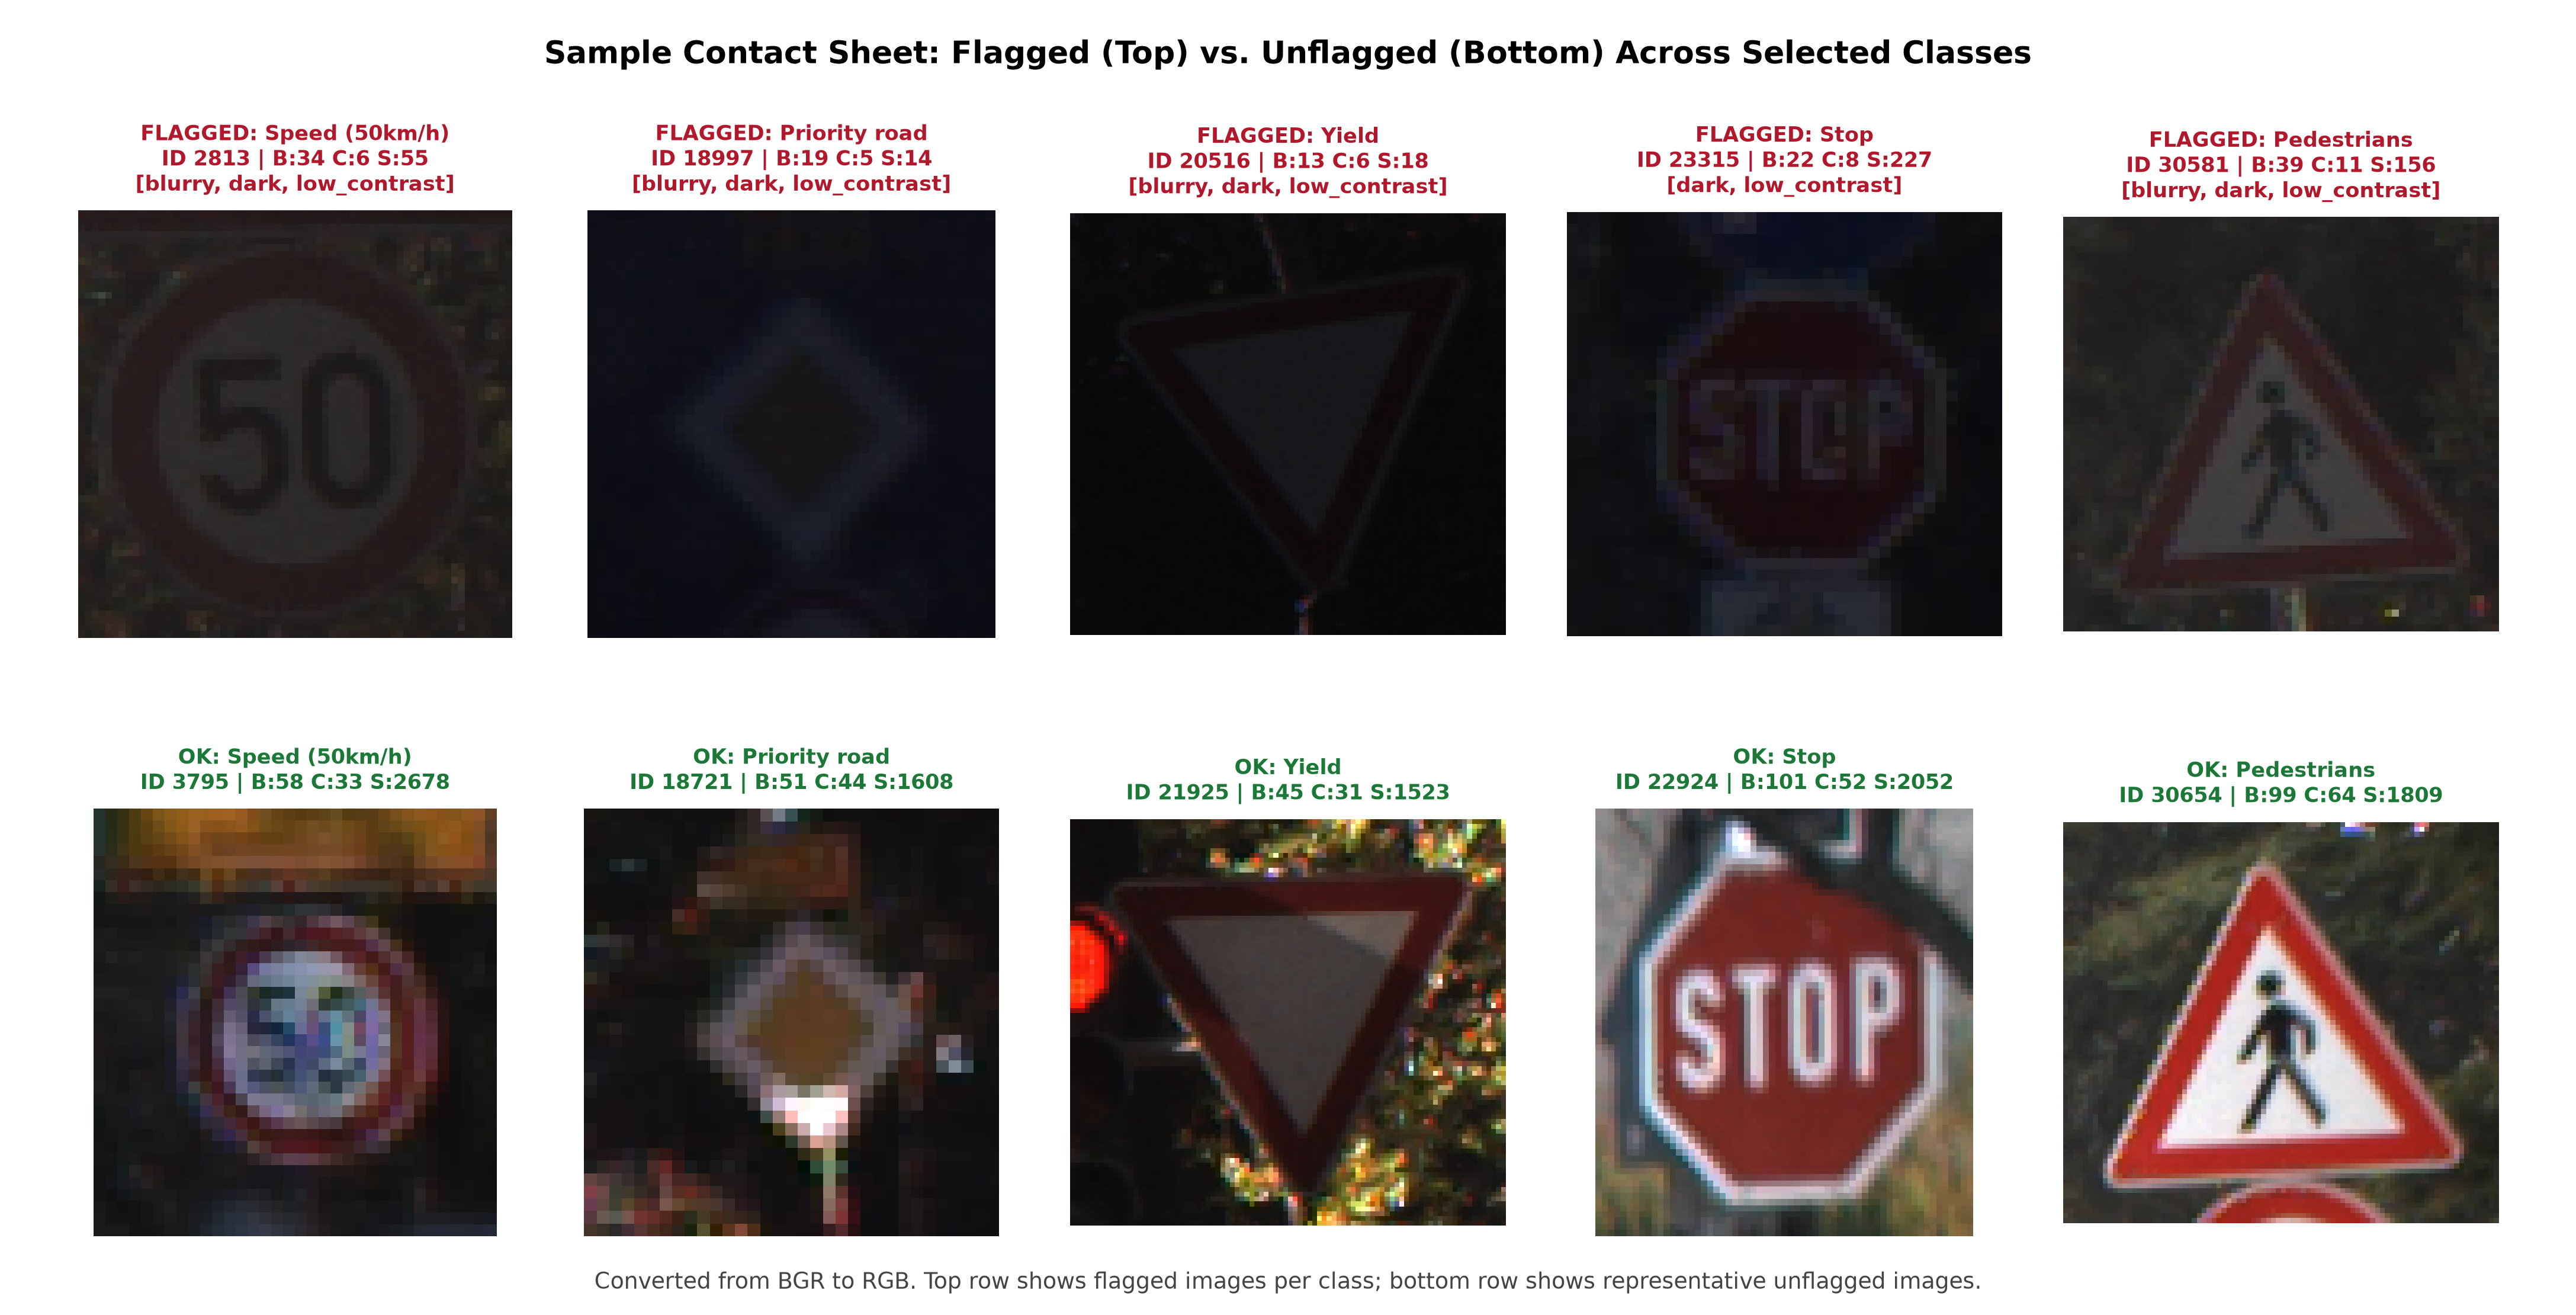

outputs/figures/fig2_brightness_sharpness_distributions.png


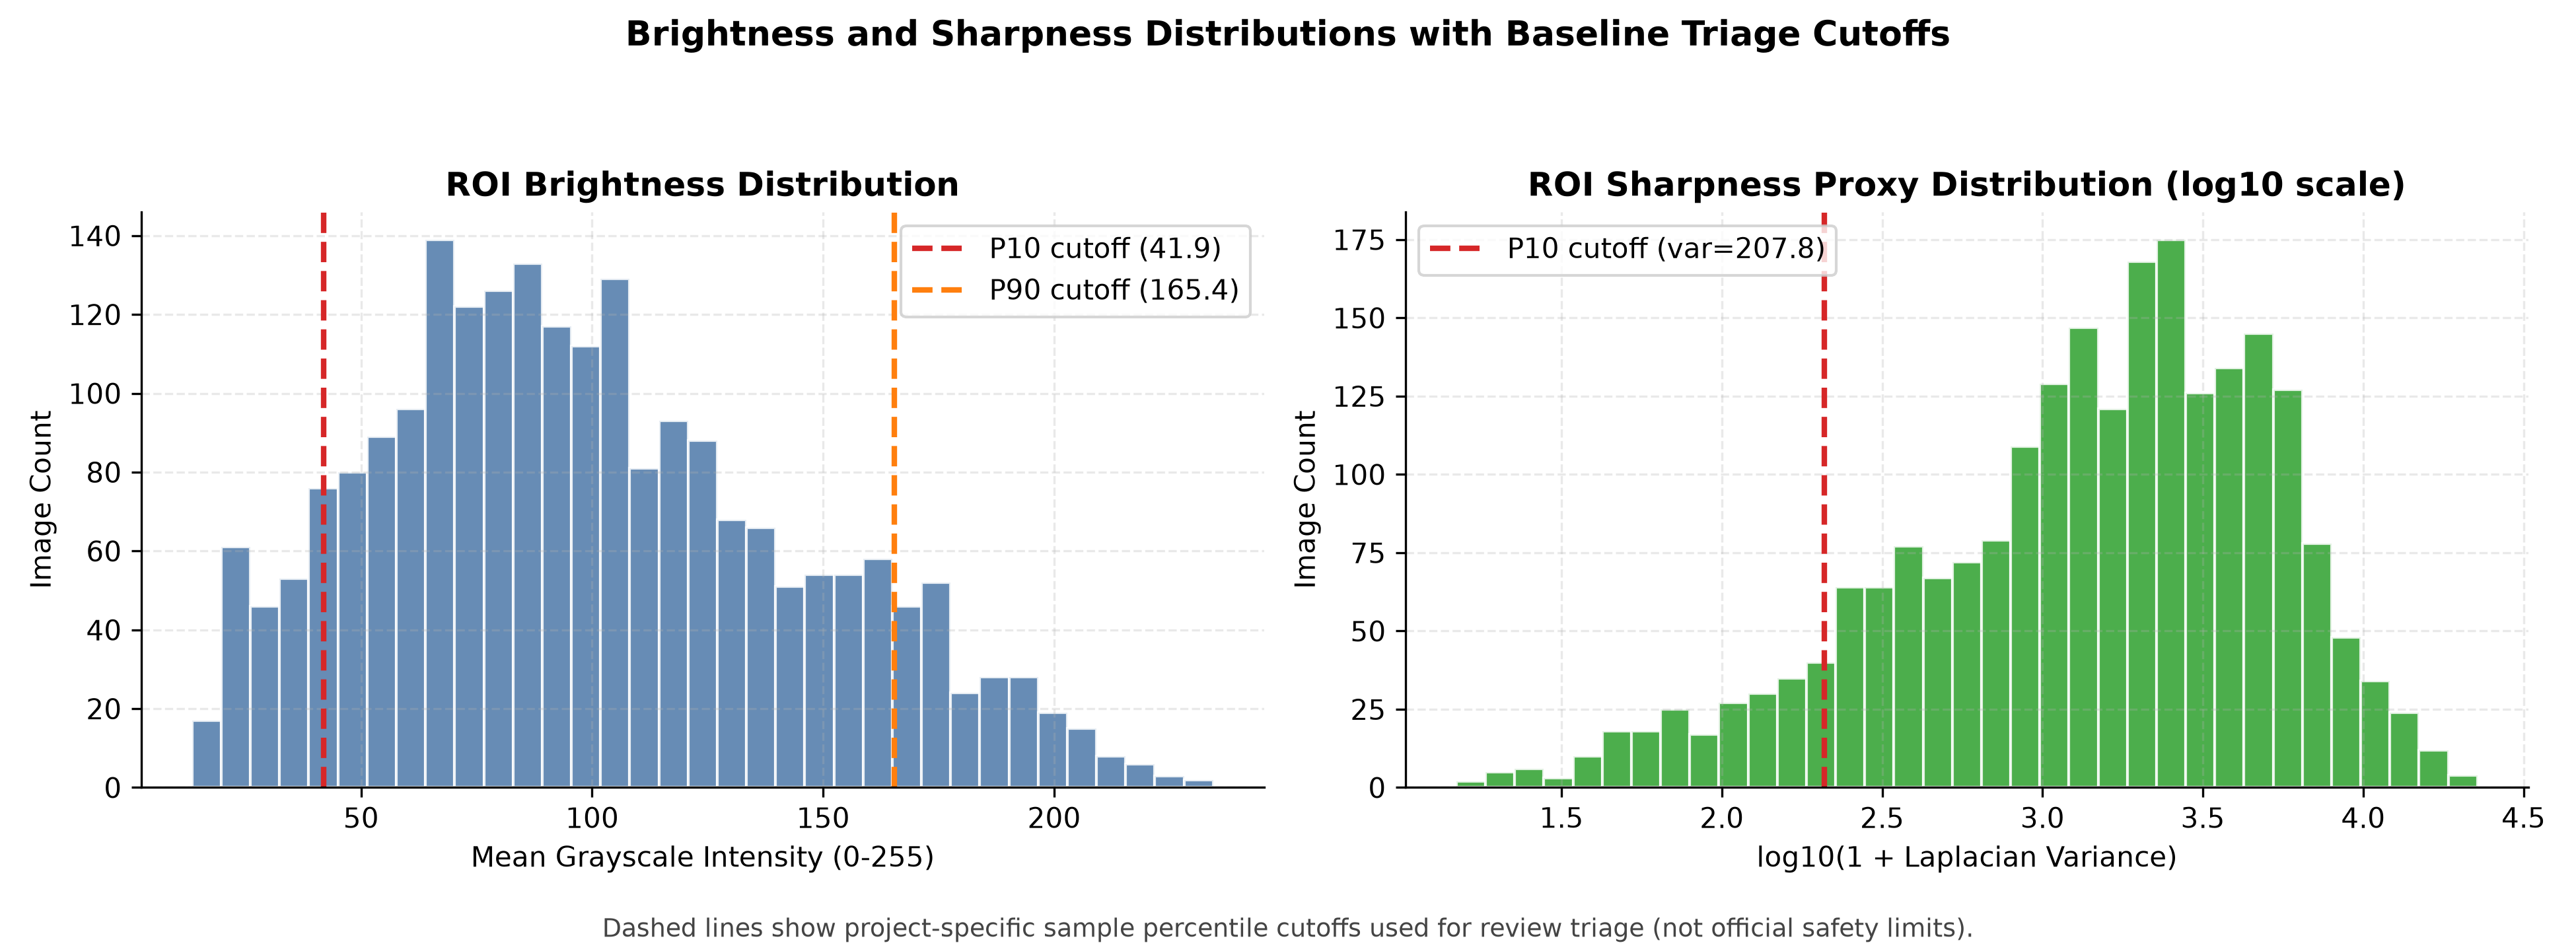

outputs/figures/fig3_class_feature_boxplots.png


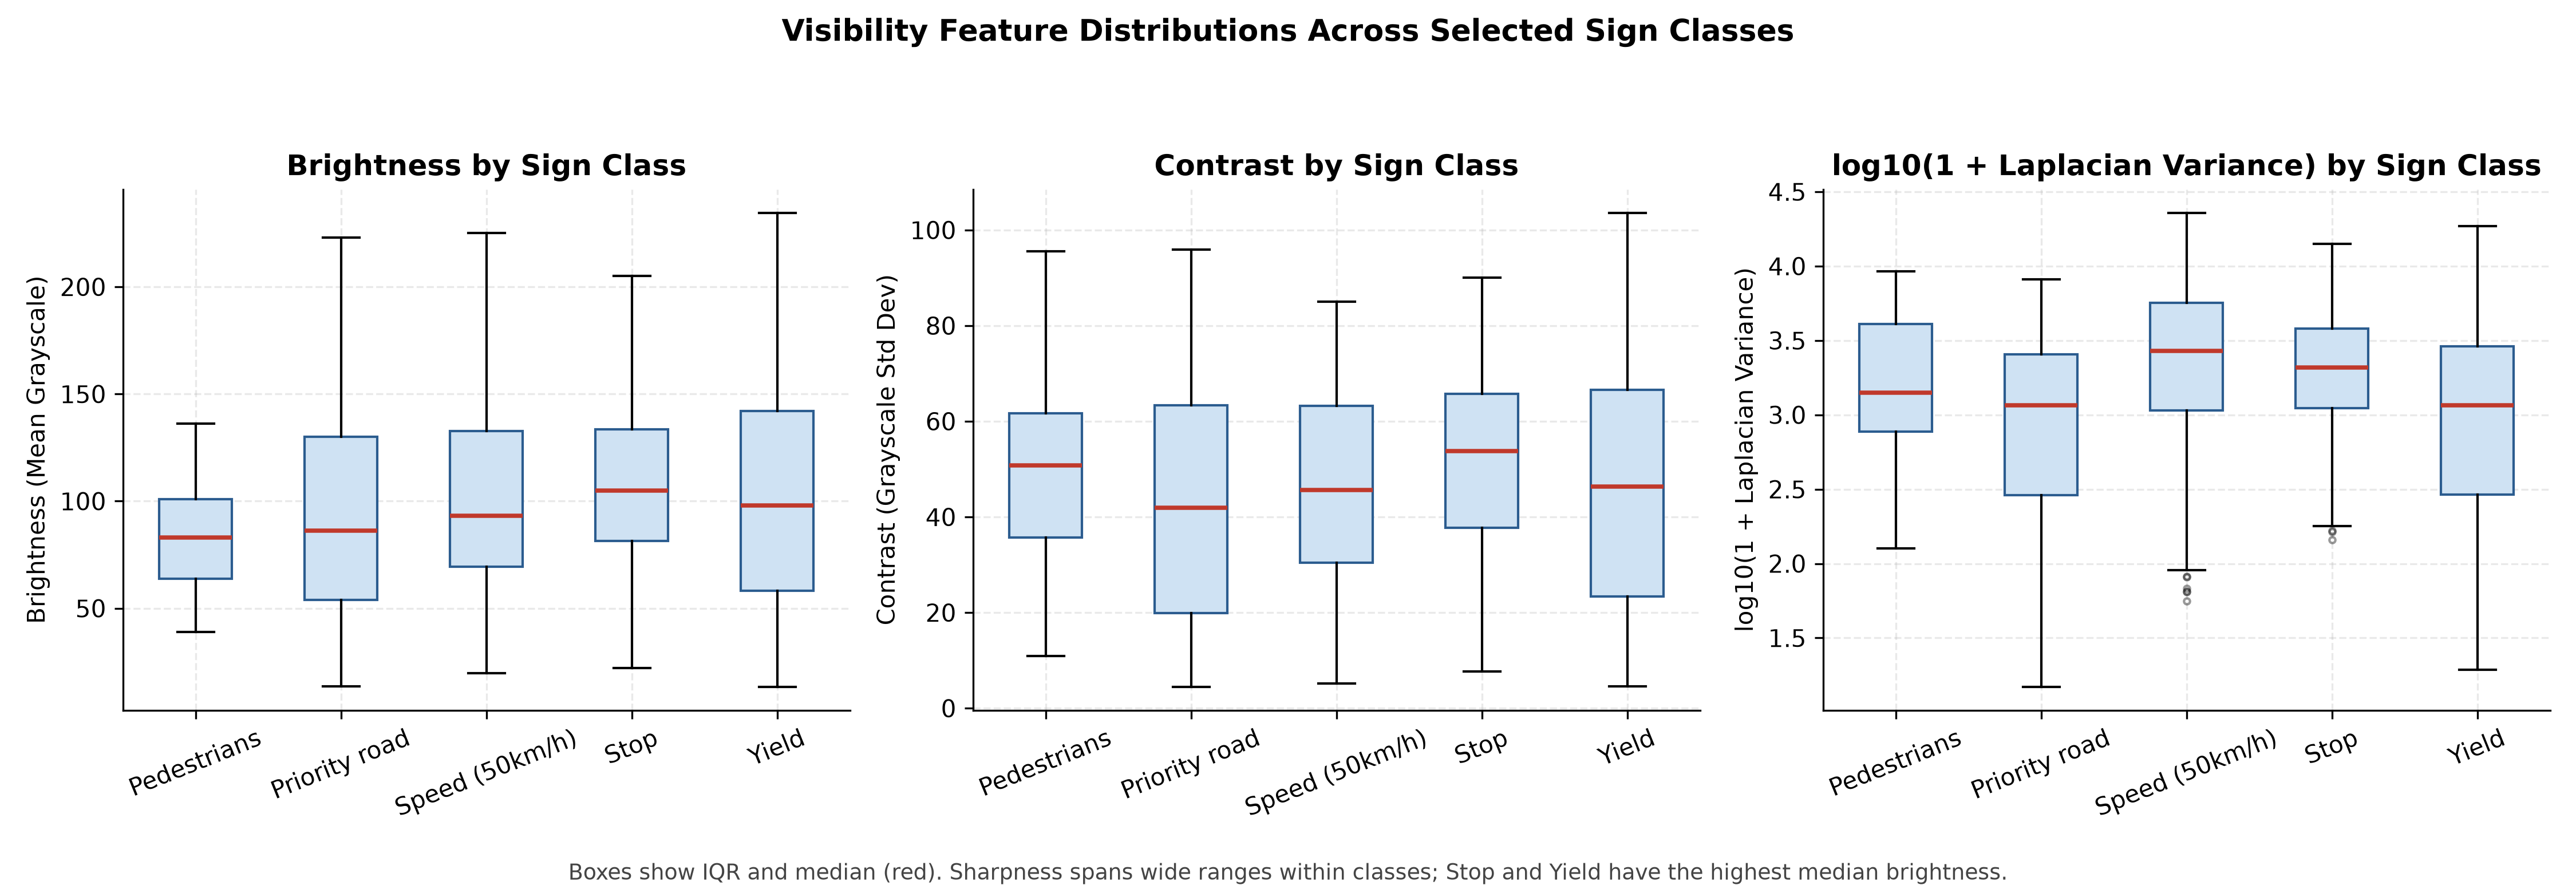

outputs/figures/fig4_flag_rate_by_class.png


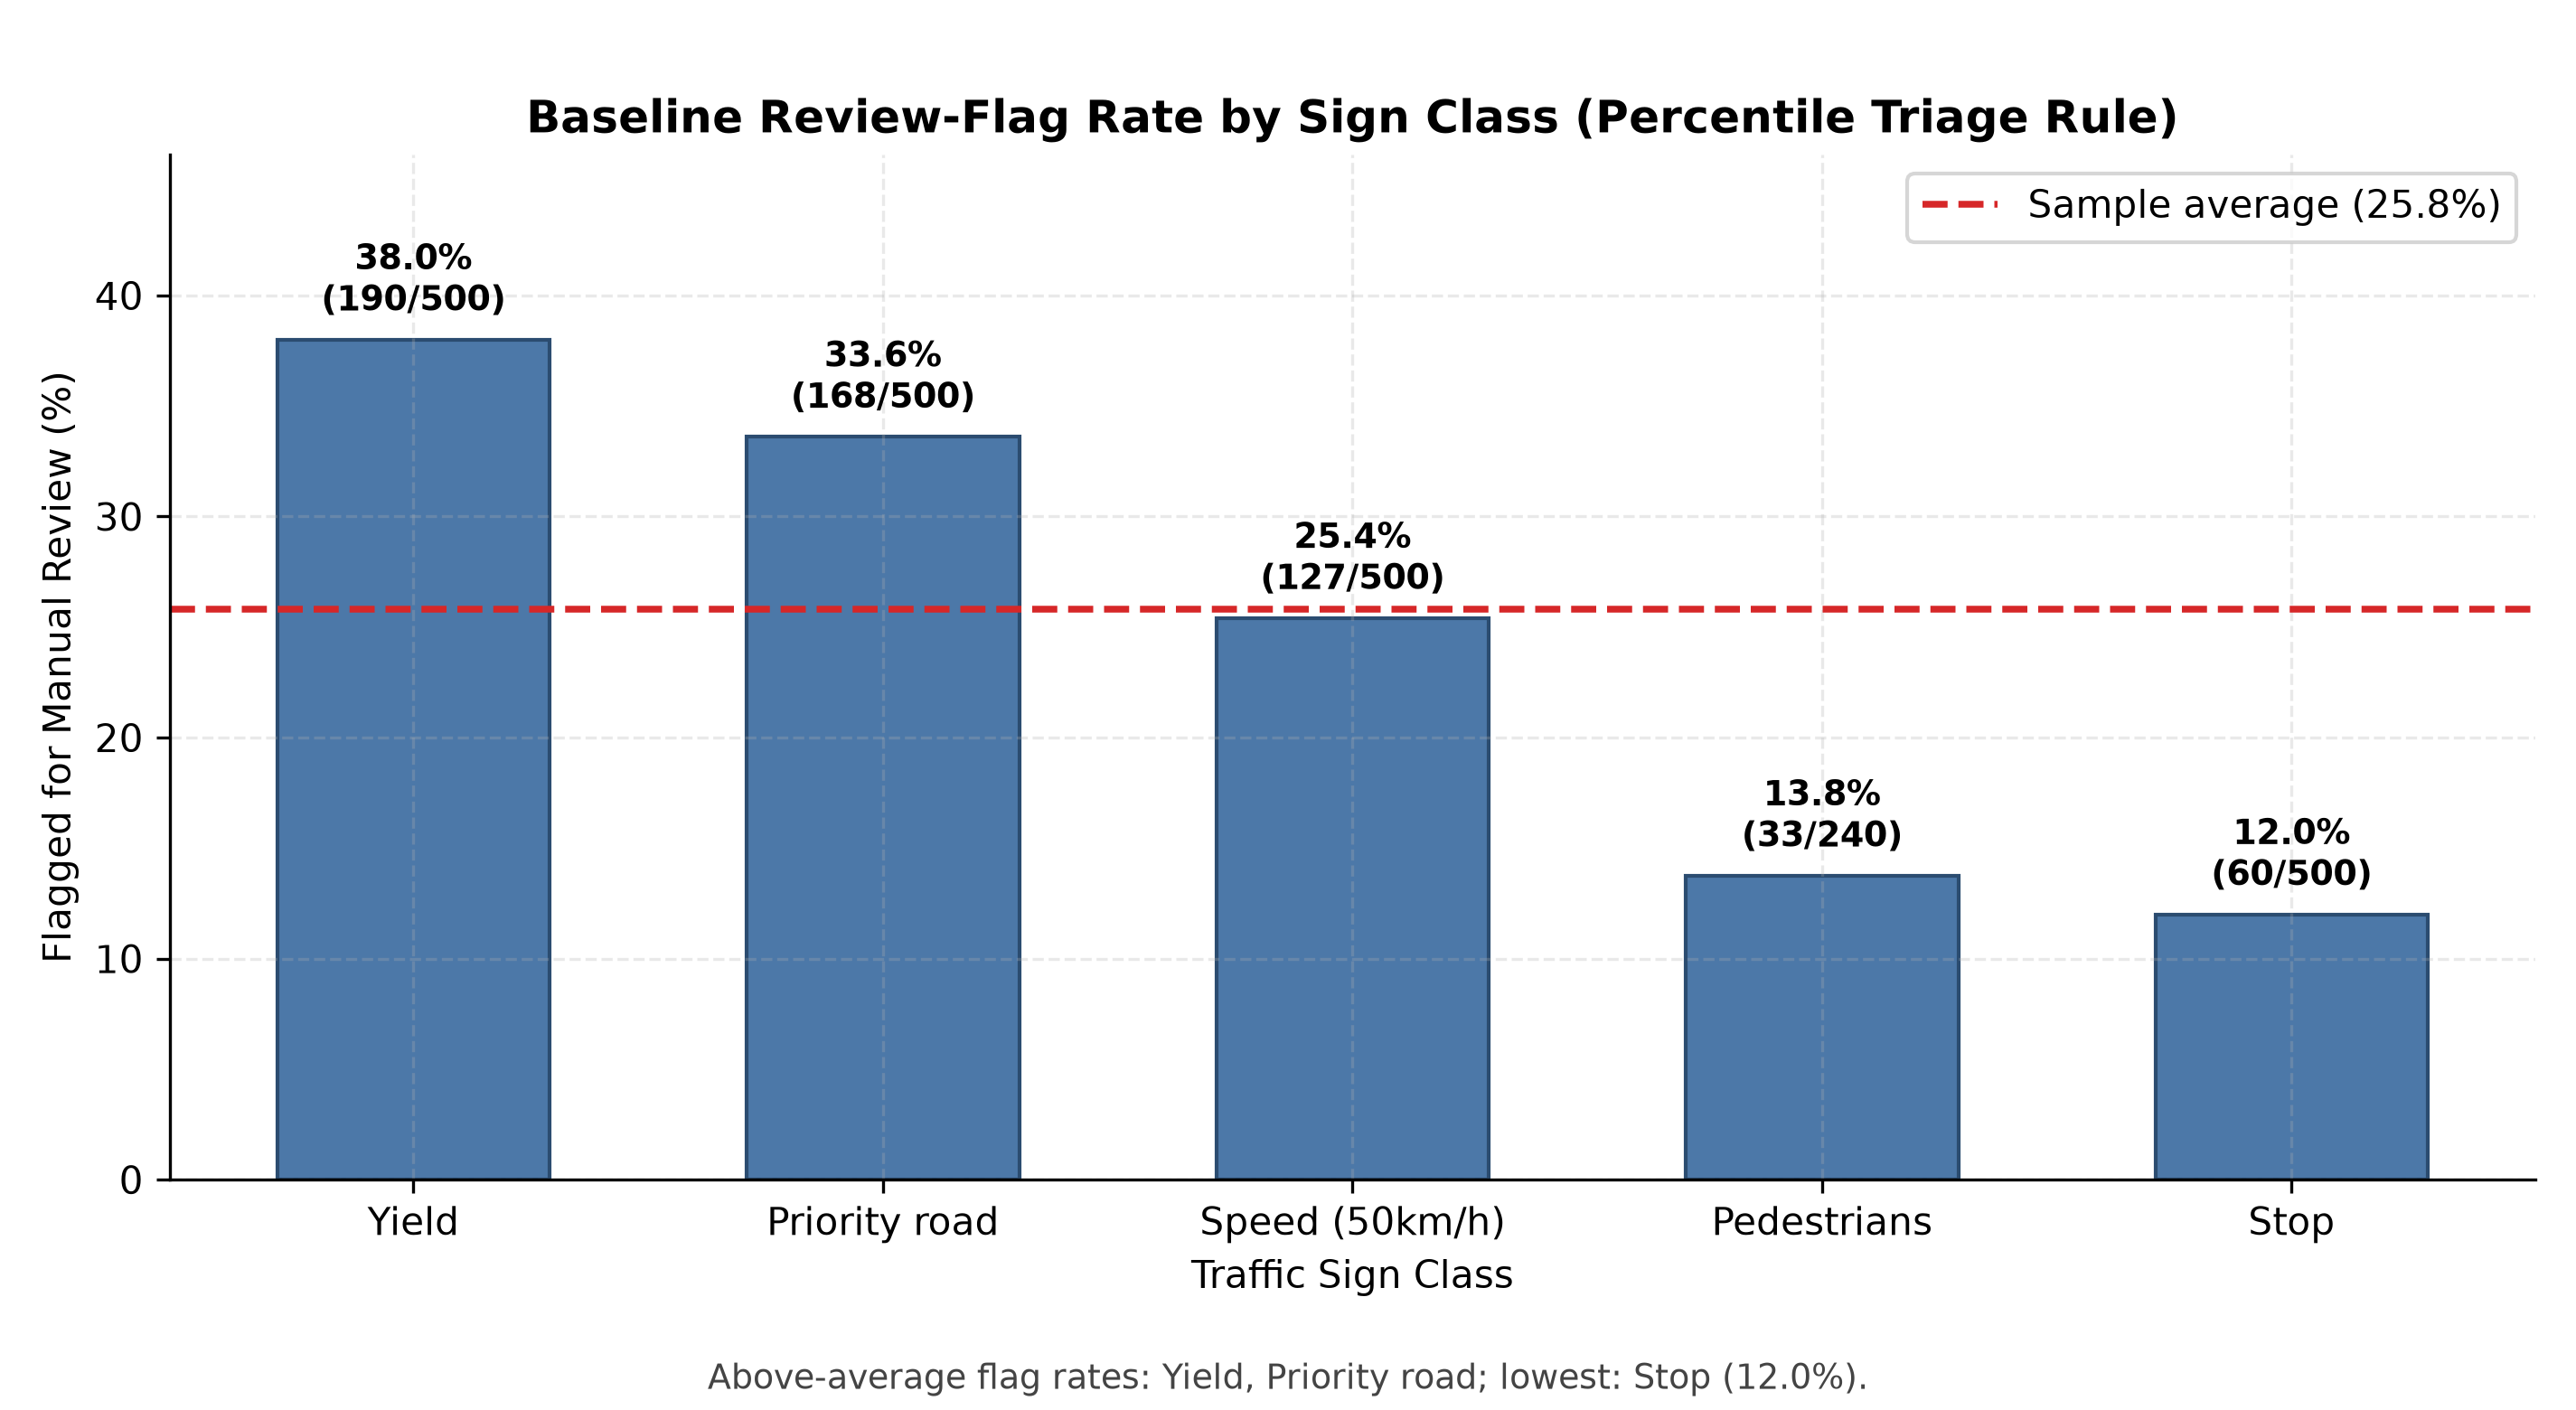

outputs/figures/fig5_size_and_contrast_by_class.png


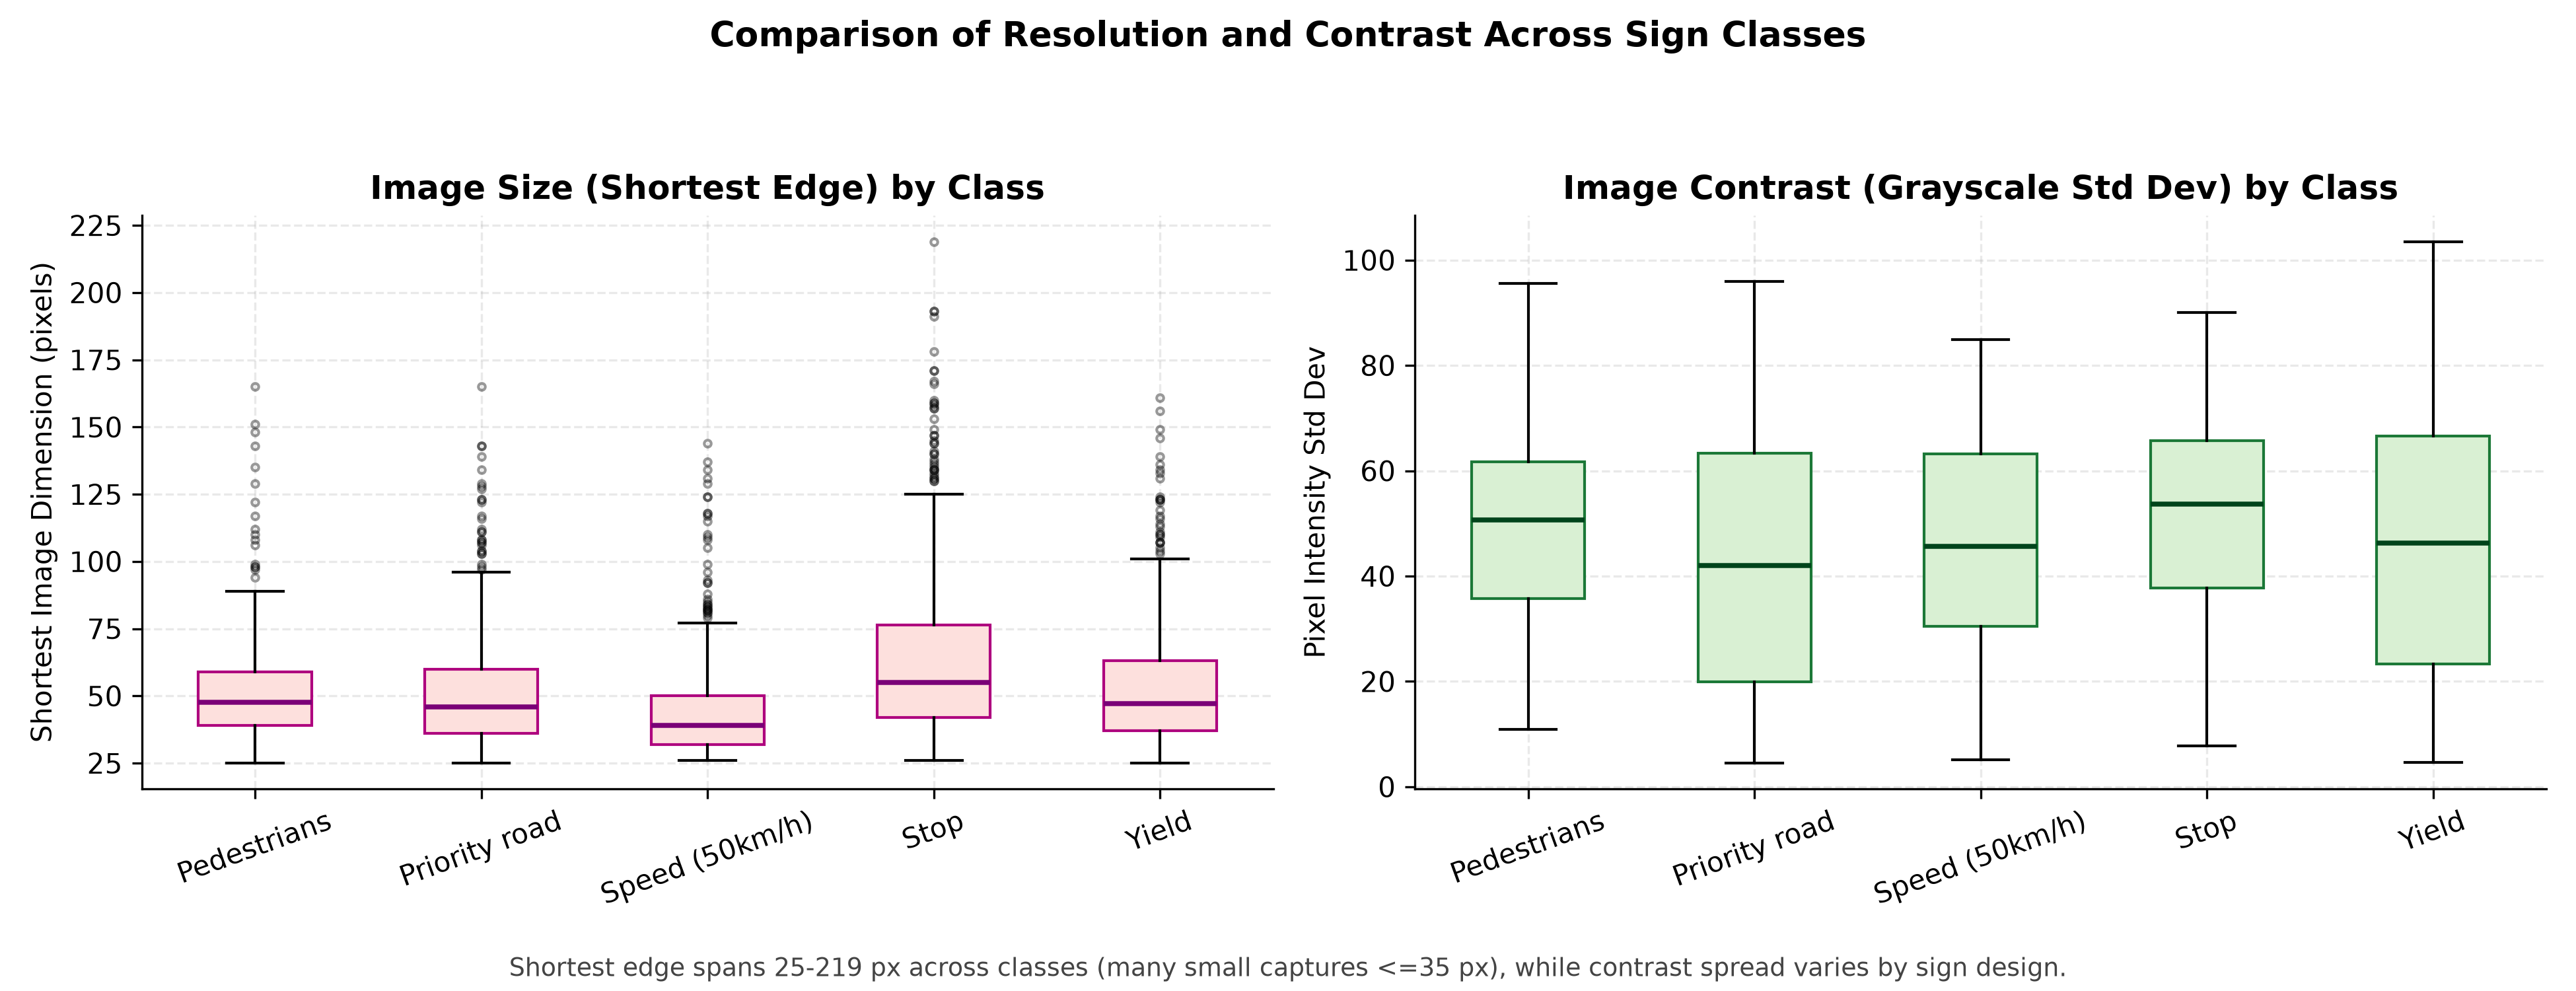

outputs/figures/fig6_sensitivity_by_class.png


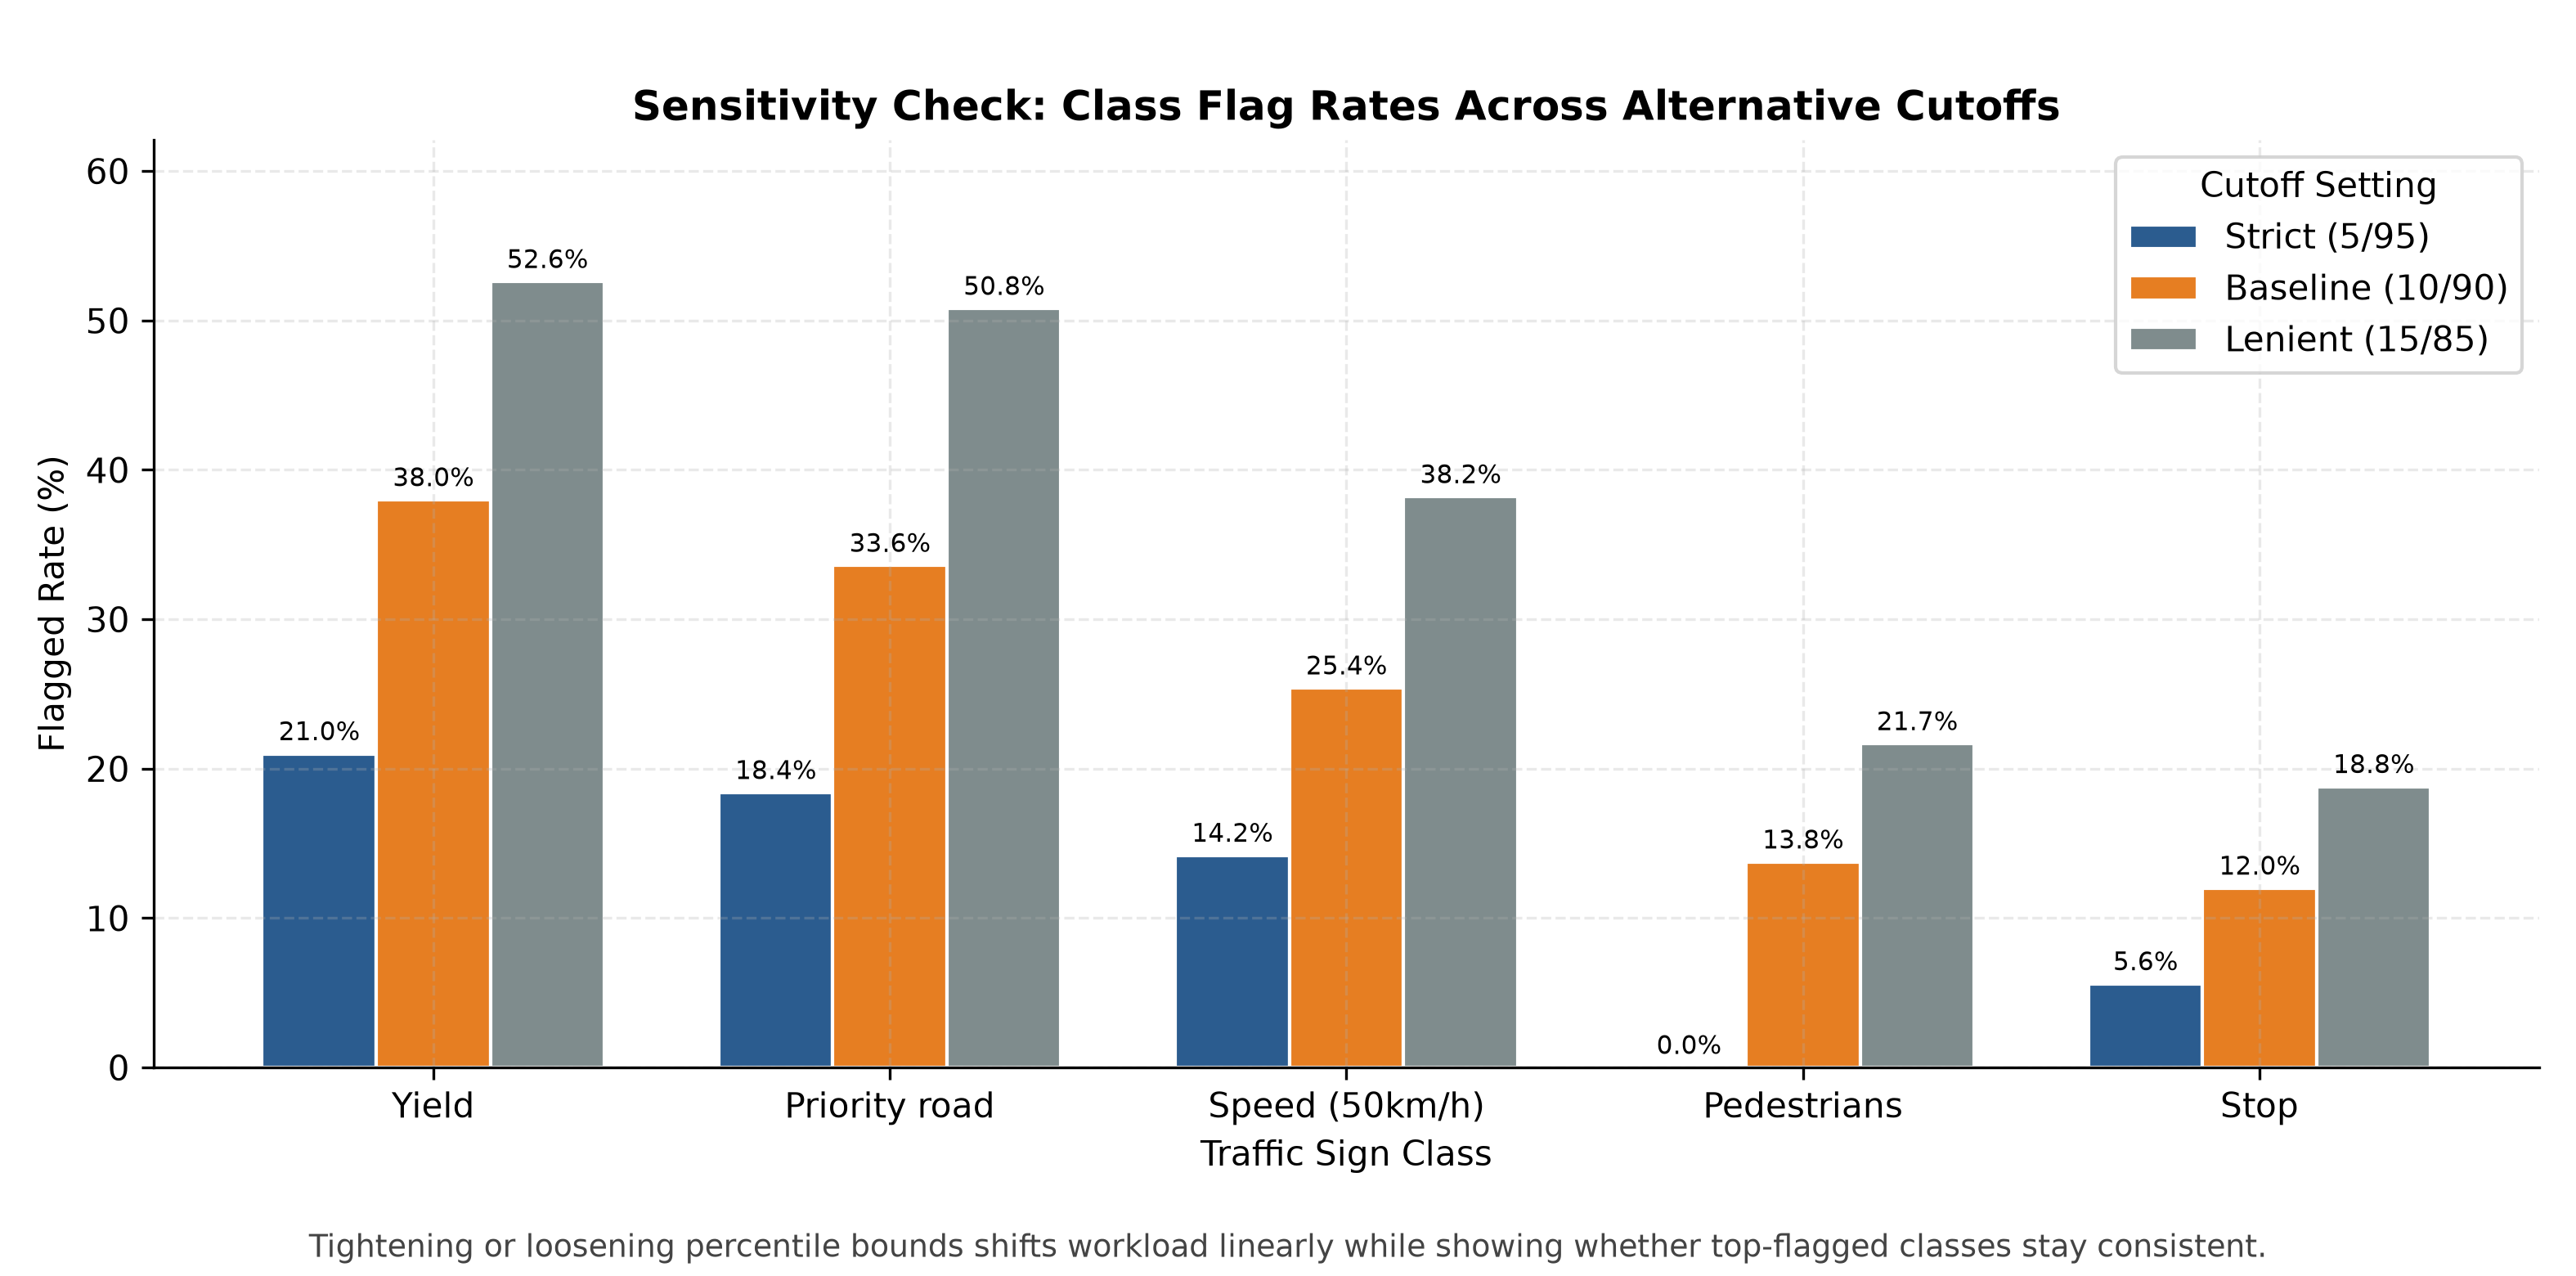

outputs/figures/fig7_three_examples.png


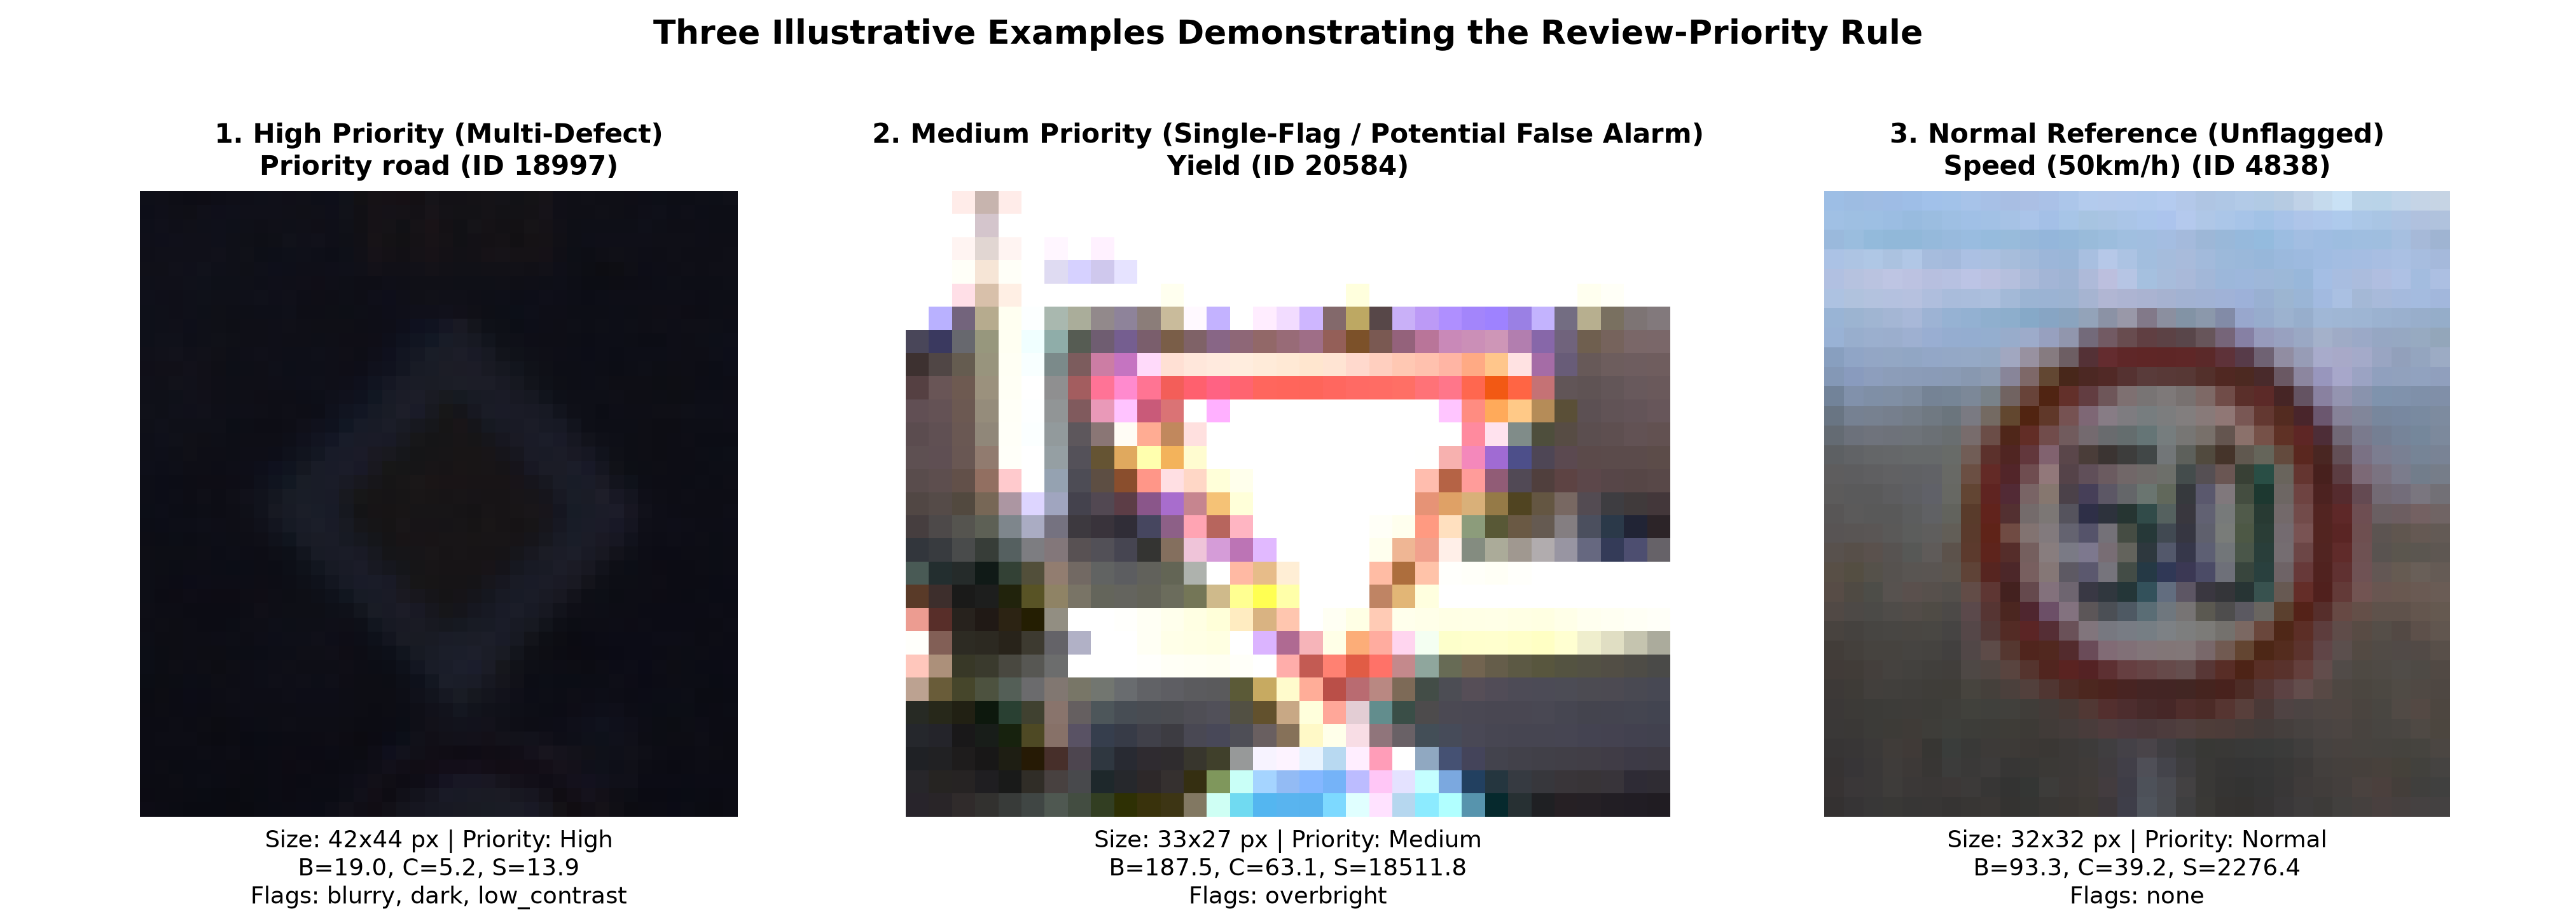

In [13]:
from pathlib import Path
from IPython.display import Image, display

for fig_file in sorted(Path("outputs/figures").glob("*.png")):
    print(fig_file.as_posix())
    display(Image(filename=str(fig_file), width=850))

## 7. `TrafficSignAudit` Workflow Class & Validation Checks (`src/audit.py`)
Organizes the full workflow in `TrafficSignAudit` and runs automated checks verifying missing/corrupted image handling, output columns, strictly boolean review flags, and relative path traceability.

In [14]:
%%writefile "src/audit.py"
"""TrafficSignAudit workflow class and automated validation checks."""

from pathlib import Path
import sys
import tempfile
import pandas as pd

ROOT = Path(__file__).resolve().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.analysis import (
    analyze_feature_associations,
    select_illustrative_examples,
    summarize_class_counts,
    summarize_features_by_class,
    summarize_flags_by_class,
)
from src.config import (
    BASELINE_CUTOFFS,
    MAX_SAMPLES_PER_CLASS,
    PROJECT_ROOT,
    RANDOM_SEED,
    SELECTED_CLASSES,
    SENSITIVITY_SCENARIOS,
    ensure_output_dirs,
)
from src.data_prep import create_stratified_sample, inspect_full_dataset, load_annotations
from src.features import compare_roi_vs_full, extract_image_features
from src.plots import generate_all_plots
from src.triage import assign_review_priority, run_sensitivity_check, save_triage_outputs


class TrafficSignAudit:
    """End-to-end manager for loading, measuring, flagging, summarizing, and plotting GTSRB signs."""

    def __init__(
        self,
        project_root: Path | None = None,
        selected_classes: dict[int, str] = SELECTED_CLASSES,
        max_per_class: int = MAX_SAMPLES_PER_CLASS,
        seed: int = RANDOM_SEED,
        cutoffs: dict[str, float] = BASELINE_CUTOFFS,
    ) -> None:
        self.project_root = Path(project_root) if project_root else PROJECT_ROOT
        self.selected_classes = dict(selected_classes)
        self.max_per_class = max_per_class
        self.seed = seed
        self.cutoffs = dict(cutoffs)
        ensure_output_dirs(self.project_root)

        self.raw_df: pd.DataFrame | None = None
        self.audit_info: dict = {}
        self.full_counts_df: pd.DataFrame | None = None
        self.sample_df: pd.DataFrame | None = None
        self.sampling_info: dict = {}
        self.features_df: pd.DataFrame | None = None
        self.extraction_stats: dict = {}
        self.roi_compare_df: pd.DataFrame | None = None
        self.triage_df: pd.DataFrame | None = None
        self.thresholds: dict = {}
        self.sensitivity_overall_df: pd.DataFrame | None = None
        self.sensitivity_by_class_df: pd.DataFrame | None = None
        self.examples_df: pd.DataFrame | None = None
        self.figure_paths: list[Path] = []

    def load_and_inspect(self) -> pd.DataFrame:
        """Load raw manifest, audit full-dataset quality, and build stratified sample."""
        manifest_path = self.project_root / "data" / "gtsrb" / "train_manifest.csv"
        self.raw_df = load_annotations(manifest_path)
        self.audit_info, self.full_counts_df = inspect_full_dataset(
            self.raw_df,
            project_root=self.project_root,
            selected_classes=self.selected_classes,
        )
        self.sample_df, self.sampling_info = create_stratified_sample(
            self.raw_df,
            selected_classes=self.selected_classes,
            max_per_class=self.max_per_class,
            seed=self.seed,
            project_root=self.project_root,
        )
        return self.sample_df

    def extract_features(self) -> pd.DataFrame:
        """Extract OpenCV metrics and compare ROI crops against full images."""
        if self.sample_df is None:
            raise RuntimeError("Call load_and_inspect() before extract_features().")
        self.features_df, self.extraction_stats = extract_image_features(
            self.sample_df, project_root=self.project_root
        )
        self.roi_compare_df = compare_roi_vs_full(
            self.sample_df, project_root=self.project_root, seed=self.seed
        )
        return self.features_df

    def apply_triage(self) -> pd.DataFrame:
        """Apply vectorized NumPy percentile triage and sensitivity checks."""
        if self.features_df is None:
            raise RuntimeError("Call extract_features() before apply_triage().")
        self.triage_df, self.thresholds = assign_review_priority(
            self.features_df, **self.cutoffs
        )
        self.sensitivity_overall_df, self.sensitivity_by_class_df = run_sensitivity_check(
            self.features_df, scenarios=SENSITIVITY_SCENARIOS
        )
        save_triage_outputs(
            self.triage_df,
            self.sensitivity_overall_df,
            self.sensitivity_by_class_df,
            project_root=self.project_root,
        )
        return self.triage_df

    def summarize(self) -> dict:
        """Run pandas groupby summaries answering all five case questions."""
        if self.triage_df is None or self.full_counts_df is None or self.sensitivity_by_class_df is None:
            raise RuntimeError("Call apply_triage() before summarize().")

        counts_cmp, count_info = summarize_class_counts(
            self.full_counts_df, self.triage_df, project_root=self.project_root
        )
        feat_summary = summarize_features_by_class(
            self.triage_df, project_root=self.project_root
        )
        flag_summary, sens_pivot, rank_changed = summarize_flags_by_class(
            self.triage_df, self.sensitivity_by_class_df, project_root=self.project_root
        )
        corr_df = analyze_feature_associations(
            self.triage_df, project_root=self.project_root
        )
        self.examples_df, borderline_df = select_illustrative_examples(
            self.triage_df, project_root=self.project_root
        )
        return {
            "counts_comparison": counts_cmp,
            "count_info": count_info,
            "feature_summary": feat_summary,
            "flag_summary": flag_summary,
            "sensitivity_pivot": sens_pivot,
            "ranking_changed": rank_changed,
            "correlations": corr_df,
            "examples": self.examples_df,
            "borderline_samples": borderline_df,
        }

    def plot_all(self) -> list[Path]:
        """Generate all Matplotlib figures."""
        if self.triage_df is None or self.sensitivity_by_class_df is None or self.examples_df is None:
            raise RuntimeError("Call summarize() before plot_all().")
        self.figure_paths = generate_all_plots(
            self.triage_df,
            self.sensitivity_by_class_df,
            self.examples_df,
            cutoffs=self.cutoffs,
            project_root=self.project_root,
        )
        return self.figure_paths

    def run_all(self) -> dict:
        """Execute the full pipeline end-to-end and return summary artifacts."""
        self.load_and_inspect()
        self.extract_features()
        self.apply_triage()
        summaries = self.summarize()
        self.plot_all()
        return summaries

    def run_validation_checks(self) -> None:
        """Verify error handling, schema completeness, boolean flags, and path portability."""
        # 1. Verify missing file and unreadable corrupted image are caught gracefully
        with tempfile.NamedTemporaryFile(
            dir=self.project_root / "outputs", suffix=".png", delete=False
        ) as tmp:
            tmp.write(b"not a real png image")
            corrupt_path = Path(tmp.name)

        try:
            corrupt_rel = corrupt_path.relative_to(self.project_root).as_posix()
            bad_rows = pd.DataFrame(
                [
                    {
                        "image_id": -1,
                        "class_id": 2,
                        "class_name": "Test missing",
                        "roi_x1": 0,
                        "roi_y1": 0,
                        "roi_x2": 10,
                        "roi_y2": 10,
                        "relative_path": "data/gtsrb/images/does_not_exist.png",
                    },
                    {
                        "image_id": -2,
                        "class_id": 2,
                        "class_name": "Test corrupt",
                        "roi_x1": 0,
                        "roi_y1": 0,
                        "roi_x2": 10,
                        "roi_y2": 10,
                        "relative_path": corrupt_rel,
                    },
                ]
            )
            bad_df, bad_stats = extract_image_features(
                bad_rows, project_root=self.project_root, save_csv=False
            )
            assert bad_df.empty, "Expected 0 valid feature rows from bad test inputs."
            assert bad_stats["skipped"]["missing_file"] == 1, "Missing file was not counted."
            assert bad_stats["skipped"]["unreadable_image"] == 1, "Corrupt image was not counted."
        finally:
            corrupt_path.unlink(missing_ok=True)

        # 2. Verify required output columns exist
        triage_df = (
            self.triage_df
            if self.triage_df is not None
            else pd.read_csv(self.project_root / "outputs" / "processed" / "triage_results.csv")
        )
        required_cols = [
            "image_id",
            "image_path",
            "class_id",
            "class_name",
            "width",
            "height",
            "brightness",
            "contrast",
            "sharpness",
            "priority_level",
            "needs_review",
        ]
        missing_cols = [c for c in required_cols if c not in triage_df.columns]
        assert not missing_cols, f"Missing expected columns in triage_results: {missing_cols}"

        # 3. Verify review flags are strictly True/False booleans with no NaNs
        assert triage_df["needs_review"].isna().sum() == 0, "needs_review contains NaNs."
        assert set(triage_df["needs_review"].unique()).issubset({True, False}), (
            "needs_review must contain only True/False values."
        )
        assert pd.api.types.is_bool_dtype(triage_df["needs_review"]), (
            "needs_review column must have boolean dtype."
        )

        # 4. Verify every row traces back to an existing relative path inside the repo
        sample_paths = triage_df["image_path"].astype(str)
        assert not sample_paths.str.contains(r":|^/|\\Users\\", regex=True).any(), (
            "Found non-relative or machine-specific path in triage_results."
        )
        missing_targets = [
            p for p in sample_paths if not (self.project_root / p).exists()
        ]
        assert not missing_targets, f"Found {len(missing_targets)} missing source files."

        print("All 4 validation checks passed (error catching, columns, boolean flags, relative traceability).")


if __name__ == "__main__":
    audit = TrafficSignAudit()
    summaries = audit.run_all()
    print(f"Full GTSRB dataset : {audit.audit_info['total_rows']:,} images across {audit.audit_info['num_classes']} classes")
    print(f"Analyzed sample    : {len(audit.triage_df):,} images across {audit.triage_df['class_id'].nunique()} classes")
    print(f"Flagged for review : {int(audit.triage_df['needs_review'].sum()):,} ({100 * audit.triage_df['needs_review'].mean():.2f}%)")
    print(f"Saved figures      : {len(audit.figure_paths)} PNGs in outputs/figures/")
    audit.run_validation_checks()

Overwriting src/audit.py


In [15]:
%run "src/audit.py"

Full GTSRB dataset : 39,209 images across 43 classes
Analyzed sample    : 2,240 images across 5 classes
Flagged for review : 578 (25.80%)
Saved figures      : 7 PNGs in outputs/figures/
All 4 validation checks passed (error catching, columns, boolean flags, relative traceability).


## Saved Outputs

- **Processed tables (`outputs/processed/`):** `full_class_counts.csv`, `sampled_annotations.csv`, `image_features.csv`, `roi_vs_full_sample.csv`, `triage_results.csv`, `sensitivity_overall.csv`, `sensitivity_by_class.csv`, `class_counts_comparison.csv`, `class_feature_summary.csv`, `class_flag_summary.csv`, `feature_correlations.csv`, `illustrative_examples.csv`.
- **Figures (`outputs/figures/`):** `fig1_contact_sheet.png` through `fig7_three_examples.png`.